# **<font color='#2E5A7A'>TP1 (TD 2-3) : Clustering sur des jeux de données réelles</font>**

> *<font color='steelblue'>Pour cet exercice pratique, vous travaillerez en groupes de 2 à 4 personnes. Vous vous placerez dans la situation d’analystes auxquels un expert du domaine considéré (médecin, journaliste, etc.) demanderait de l’aide pour explorer des données qu’il a collectées et qu’il ne sait pas encore interpréter.</font>*

> *<font color='steelblue'>Votre notebook constitue le rapport que vous lui remettriez. Il devra donc contenir non seulement le code et les informations techniques concernant les méthodes d’analyse de données utilisées, mais également vos résultats sous forme de textes et/ou de visualisations graphiques, vos conclusions et les interprétations dans le contexte du domaine étudié. Le notebook devra être suffisamment clair et explicite pour que l’expert puisse comprendre votre démarche et vos conclusions, même sans maîtriser les méthodes informatiques utilisées.</font>*

- **<font color='steelblue'>Consignes**
  - **Groupes :** formez des groupes de ***2 à 4 personnes*** au choix.
  - **Choix du dataset :** choissez votre jeu de données parmi ceux qui vous seront proposés. Faites valider ce choix par l'encadrant du cours.
  - **Format du projet :** le projet est composé de ***2 TP*** correspondant à un notebook chacun. Pour chacun des TP, vous aurez deux séances en classes pour y travailler. Vous devrez rendre chacun des TP à la date indiquée. Vous serez évélués sur ces rendus mais aussi lors d'une soutenance orale en fin de semestre.
  - **Remise du TP1 :** le notebook est à remettre en ligne sur ***eCampus ou par mail*** début Novembre.
  - **Contact :** (mettre toutes les adresses mails en destinataires ou copies) massinissa.hamidi@univ-evry.fr , judith.coutrot@univ-evry.fr et fatma.chamekh@universite-paris-saclay.fr .
</font>


- **<font color='steelblue'>Conseils pratiques**
  - Le TP est volontairement exploratoire. Appliquez les méthodes d'analyse de données étudiées en cours et explorez les résultats.
  - Remplissez les différentes parties de ce notebook soit avec du code, soit avec des interprétations écrites.
  - Des notebooks d'aide pour chaque méthode vous sont fournis et peuvent vous donner des pistes de recherche mais n'hésitez pas à aller plus loin, explorer d'autres visualisations si cela vous semble pertinent.
  - Des librairies et fonctions sont importées au début du notebook. Vous pouvez aller regarder leurs documentations car celles-ci vous aideront.
  - Votre note dépendra principalement de la qualité de vos interprétations ; veillez à replacer vos conclusions dans le contexte de votre ensemble de données.
</font>

---

## **<font color='#2E5A7A'>I. Introduction</font>**

### <font color='#2E5A7A'>0. Installation et import des bibliothèques</font>

La cellule ci-dessous **vérifie** que les bibliothèques nécessaires sont présentes et **installe automatiquement** celles qui manquent (à exécuter en premier). Si une installation a lieu, il peut être nécessaire de relancer le noyau (*Kernel → Restart*) puis de réexécuter le notebook depuis le début.

In [1]:
# Vérification et installation automatique des bibliothèques manquantes
import importlib.util
import subprocess
import sys

# nom du module à importer -> nom du paquet à installer avec pip
REQUIS = {
    "numpy": "numpy",
    "pandas": "pandas",
    "matplotlib": "matplotlib",
    "seaborn": "seaborn",
    "sklearn": "scikit-learn",
    "scipy": "scipy",
    "openpyxl": "openpyxl",   # lecture du fichier Excel d'origine
}

manquants = [pip_name for module, pip_name in REQUIS.items()
             if importlib.util.find_spec(module) is None]

if manquants:
    print("Installation des bibliothèques manquantes :", ", ".join(manquants))
    subprocess.check_call([sys.executable, "-m", "pip", "install", "--quiet", *manquants])
    print("Installation terminée. Si une erreur d'import apparaît ensuite, relancez le noyau.")
else:
    print("Toutes les bibliothèques nécessaires sont déjà installées.")

Toutes les bibliothèques nécessaires sont déjà installées.


In [2]:
# Manipulation des tables
import numpy as np
import pandas as pd
from pathlib import Path
from IPython.display import display

# Graphiques et visualisations
import matplotlib.pyplot as plt
import seaborn as sns

# Pré-traitement
from sklearn.preprocessing import StandardScaler

# Analyse de données : les trois méthodes du projet
from sklearn.cluster import KMeans, AgglomerativeClustering, SpectralClustering
from sklearn.decomposition import PCA
from sklearn.neighbors import kneighbors_graph

# Critères d'évaluation (tous non supervisés, sauf l'ARI qui compare deux partitions entre elles)
from sklearn.metrics import (silhouette_score, silhouette_samples,
                             calinski_harabasz_score, adjusted_rand_score)

# Outils pour le dendrogramme et le graphe de voisinage
from scipy.cluster.hierarchy import dendrogram, linkage
from scipy.sparse.csgraph import laplacian

import warnings
warnings.filterwarnings("ignore")

sns.set_theme(style="whitegrid")
pd.set_option("display.width", 200)
RS = 0   # graine aléatoire commune : les résultats sont reproductibles

### <font color='#2E5A7A'>A. Présentation du jeu de données</font>

- <font color='steelblue'>Présentez le jeu de données. Quels enjeux représente t-il ? Pensez à plusieurs problématiques auquelles vous pouvez vous intéresser grâce aux méthodes étudiées en cours.
</font>

#### Contexte et objectif

Ce travail porte sur **2 500 graines de courge** décrites par **12 mesures** issues de leur contour, extraites automatiquement à partir de photographies (Koklu, Sarigil et Ozbek, 2021). Certaines variables parlent de la taille (`Area`, `Perimeter`, `Convex_Area`, `Equiv_Diameter`), d'autres de la géométrie (`Major_Axis_Length`, `Minor_Axis_Length`) et d'autres de la forme (`Roundness`, `Aspect_Ration`, `Eccentricity`, etc.).

Le fichier d'origine contient aussi une colonne `Class` (la variété de la graine). **Nous ne l'utilisons jamais** : elle est retirée dès l'import et n'apparaît dans aucun calcul ni aucun graphique. L'objectif n'est pas de retrouver une classe connue à l'avance, mais de voir si les graines se regroupent *naturellement* selon leurs caractéristiques géométriques, comme le ferait un analyste qui découvre un lot sans étiquette.

La question pratique est donc la suivante : **peut-on résumer ce lot par quelques profils de graines suffisamment compréhensibles pour aider un agronome ou un trieur ?** Un tri automatique par caméra est un enjeu concret pour la filière : aujourd'hui, le tri est long et en grande partie manuel.

#### Les 12 variables

Toutes les mesures sont calculées automatiquement à partir de l'image du contour de chaque graine.

| Variable | Ce qu'elle mesure |
|---|---|
| `Area` | surface de la graine |
| `Perimeter` | longueur du contour |
| `Convex_Area` | surface de la plus petite enveloppe convexe qui entoure la graine |
| `Equiv_Diameter` | diamètre d'un disque qui aurait la même surface |
| `Major_Axis_Length` | longueur de la graine (axe le plus long) |
| `Minor_Axis_Length` | largeur de la graine (axe le plus court) |
| `Aspect_Ration` | rapport longueur / largeur : plus il est grand, plus la graine est allongée |
| `Eccentricity` | excentricité de l'ellipse équivalente (0 = cercle, proche de 1 = très allongée) |
| `Compactness` | diamètre équivalent divisé par la longueur |
| `Roundness` | rondeur (1 = cercle parfait) |
| `Solidity` | surface divisée par la surface convexe : proche de 1 si la graine n'a pas de creux |
| `Extent` | part de la boîte englobante occupée par la graine |

Source des données : Koklu, Sarigil et Ozbek (2021), *The use of machine learning methods in classification of pumpkin seeds*, Genetic Resources and Crop Evolution.

#### Problématiques

Les méthodes de clustering étudiées en cours (K-means, clustering hiérarchique, clustering spectral) permettent de s'intéresser à plusieurs questions :

- **Profils de graines** : le lot se découpe-t-il en groupes de graines qui se ressemblent (par la taille, par la forme) ?
- **Redondance** : toutes les mesures sont-elles nécessaires, ou plusieurs décrivent-elles la même chose ?
- **Robustesse** : les groupes obtenus dépendent-ils de la méthode utilisée et du choix des variables ?
- **Structure des données** : y a-t-il des groupes bien séparés, ou plutôt un continuum de formes avec une zone intermédiaire ?
- **Utilité pratique** : ces groupes peuvent-ils aider à décrire un lot, le contrôler ou préparer un tri automatique ?
- **Choix de méthode** : quelle méthode est la plus adaptée à ce type de données ?

### <font color='#2E5A7A'>B. Pré-traitement des données</font>

- <font color='steelblue'>Importez vos données et apportez des traitements nécessaires aux analyses que vous voulez réaliser (standardisation, valeurs manquantes, ...).</font>
- <font color='steelblue'>Pour cette partie, vous pouvez vous référer (sans vous limiter) au notebook d'aide du TD1:</font><font color='red'> help_basics.ipynb.</font>
- <font color='steelblue'>Enregistrez vos données pré-traitées pour la suite du projet.</font>

#### B.1 Import et inspection

In [3]:
# Chargement : on cherche d'abord le CSV commun du groupe, puis le fichier Excel d'origine.
COLS_12 = ["Area", "Perimeter", "Major_Axis_Length", "Minor_Axis_Length", "Convex_Area",
           "Equiv_Diameter", "Eccentricity", "Solidity", "Extent", "Roundness",
           "Aspect_Ration", "Compactness"]

def charger_donnees():
    """Retourne le tableau brut (avec éventuellement la colonne Class) et la source utilisée."""
    csv_candidats = ["pumpkin_selected_12_raw.csv", "Pumpkin_Seeds_Dataset.csv",
                     "Pumpkin_Seeds_Dataset/Pumpkin_Seeds_Dataset.csv"]
    xlsx_candidats = ["Pumpkin_Seeds_Dataset/Pumpkin_Seeds_Dataset.xlsx",
                      "Pumpkin_Seeds_Dataset.xlsx"]
    for chemin in csv_candidats:
        if Path(chemin).exists():
            return pd.read_csv(chemin), chemin
    for chemin in xlsx_candidats:
        if Path(chemin).exists():
            return pd.read_excel(chemin), chemin
    raise FileNotFoundError(
        "Aucun fichier de données trouvé. Placez à côté du notebook l'un de ces fichiers : "
        + ", ".join(csv_candidats + xlsx_candidats))

df_brut, source = charger_donnees()
print("Fichier utilisé :", source)

# La variété (Class) est retirée dès l'import : elle ne sera jamais utilisée.
df = df_brut.drop(columns=["Class"], errors="ignore")
assert set(df.columns) == set(COLS_12), "Colonnes inattendues dans le fichier de données"
df = df[COLS_12].copy()

# Enregistrement du CSV commun (12 variables brutes) s'il n'existe pas encore
if not Path("pumpkin_selected_12_raw.csv").exists():
    df.to_csv("pumpkin_selected_12_raw.csv", index=False)

print("Dimensions :", df.shape)
display(df.head())
print("Valeurs manquantes :", df.isna().sum().sum(), "| Doublons :", df.duplicated().sum())
display(df.describe().T.round(3))

Fichier utilisé : Pumpkin_Seeds_Dataset/Pumpkin_Seeds_Dataset.xlsx
Dimensions : (2500, 12)


,Area,Perimeter,Major_Axis_Length,Minor_Axis_Length,Convex_Area,Equiv_Diameter,Eccentricity,Solidity,Extent,Roundness,Aspect_Ration,Compactness
0,56276,888.242,326.1485,220.2388,56831,267.6805,0.7376,0.9902,0.7453,0.8963,1.4809,0.8207
1,76631,1068.146,417.1932,234.2289,77280,312.3614,0.8275,0.9916,0.7151,0.8440,1.7811,0.7487
2,71623,1082.987,435.8328,211.0457,72663,301.9822,0.8749,0.9857,0.7400,0.7674,2.0651,0.6929
3,66458,992.051,381.5638,222.5322,67118,290.8899,0.8123,0.9902,0.7396,0.8486,1.7146,0.7624
4,66107,998.146,383.8883,220.4545,67117,290.1207,0.8187,0.9850,0.6752,0.8338,1.7413,0.7557


Valeurs manquantes : 0 | Doublons : 0


,count,mean,std,min,25%,50%,75%,max
Area,2500.0,80658.221,13664.510,47939.000,70765.000,79076.000,89757.500,136574.000
Perimeter,2500.0,1130.279,109.256,868.485,1048.830,1123.672,1203.340,1559.450
Major_Axis_Length,2500.0,456.602,56.236,320.845,414.958,449.497,492.738,661.911
Minor_Axis_Length,2500.0,225.795,23.297,152.172,211.246,224.703,240.673,305.818
Convex_Area,2500.0,81508.084,13764.093,48366.000,71512.000,79872.000,90797.750,138384.000
Equiv_Diameter,2500.0,319.334,26.892,247.058,300.168,317.305,338.057,417.003
Eccentricity,2500.0,0.861,0.045,0.492,0.832,0.864,0.897,0.948
Solidity,2500.0,0.989,0.003,0.919,0.988,0.990,0.992,0.994
Extent,2500.0,0.693,0.061,0.468,0.659,0.713,0.740,0.830
Roundness,2500.0,0.792,0.056,0.555,0.752,0.798,0.834,0.940


**Lecture.** Le jeu de données contient 2 500 graines et 12 variables numériques, sans valeur manquante ni doublon, et la colonne `Class` a été retirée dès l'import. Il n'y a donc **pas d'imputation à faire**. Les moyennes et écarts-types montrent des échelles très différentes d'une variable à l'autre (`Area` de l'ordre de 80 000, `Solidity` proche de 1) : une standardisation sera nécessaire avant tout calcul de distance.

#### B.2 Distributions

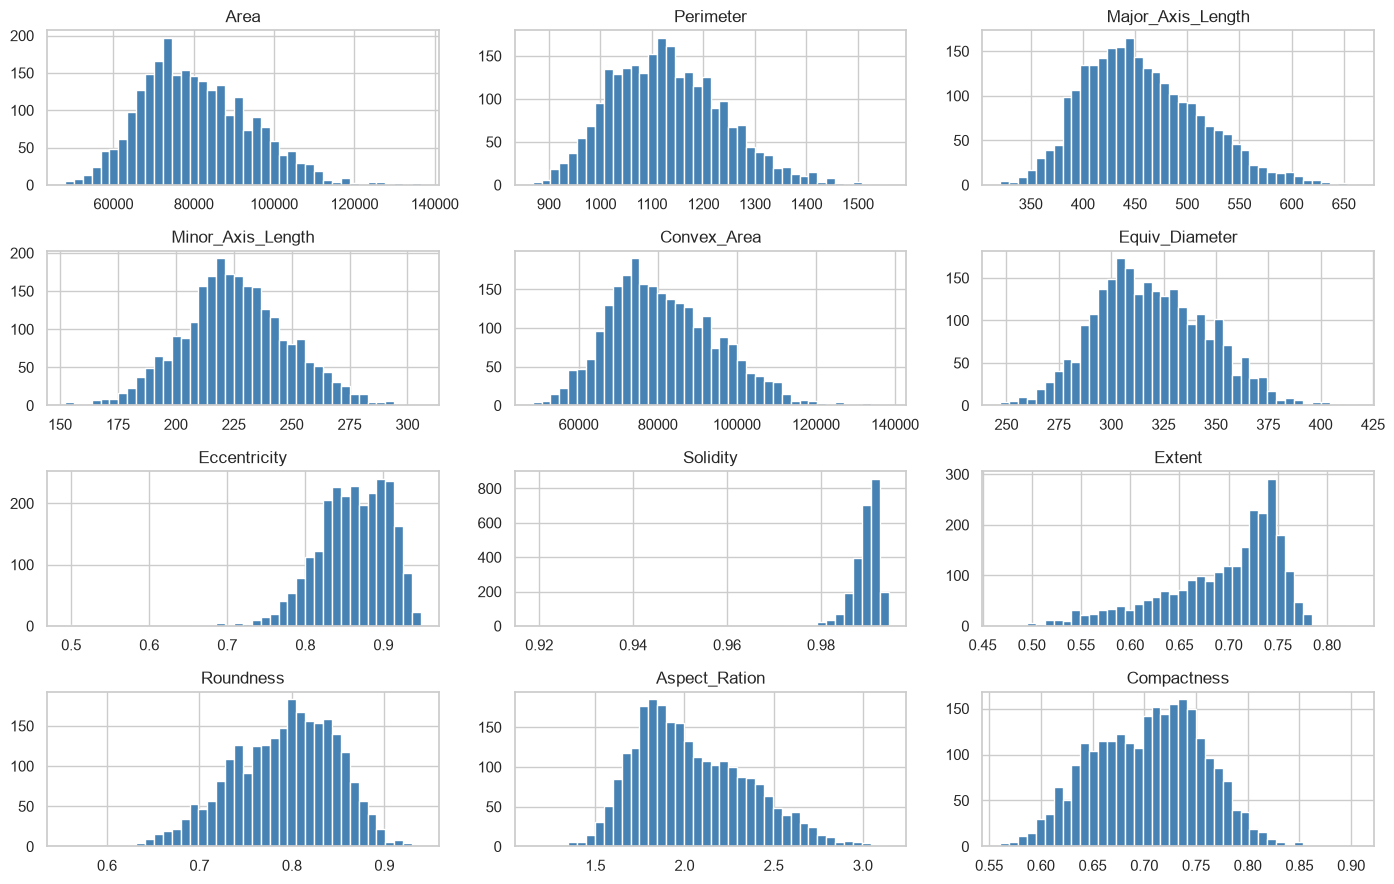

In [4]:
df.hist(bins=40, figsize=(14, 9), color="steelblue")
plt.tight_layout(); plt.show()

**Lecture.** Les variables de taille (`Area`, `Perimeter`, `Major_Axis_Length`) sont plutôt en cloche, légèrement étalées vers les grandes valeurs. `Solidity` est très concentrée près de 0,99 avec une longue queue vers les faibles valeurs (asymétrie forte, environ −5,7) : presque toutes les graines sont « pleines » (sans creux), quelques-unes sont irrégulières. `Extent` est lui aussi asymétrique vers le bas. Aucune variable ne présente deux bosses nettes : il n'y a pas de séparation évidente en deux populations sur une variable isolée, ce qui annonce que les groupes se recouvriront.

#### B.3 Feature engineering : redondance entre variables
Plusieurs variables mesurent presque la même chose. Si on les garde toutes, la « taille » compterait plusieurs fois dans les distances et dominerait le clustering.

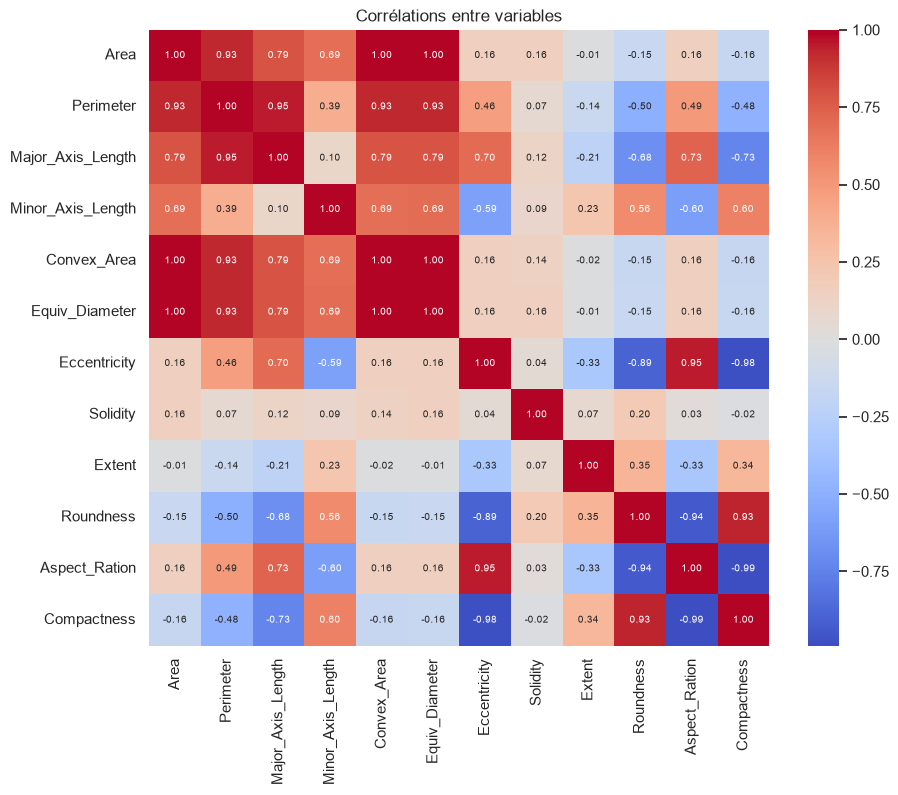

,var1,var2,corr
0,Area,Convex_Area,0.999806
1,Area,Equiv_Diameter,0.998464
2,Convex_Area,Equiv_Diameter,0.998289
5,Aspect_Ration,Compactness,-0.990778
4,Eccentricity,Compactness,-0.981689
3,Eccentricity,Aspect_Ration,0.950225


In [5]:
corr = df.corr()
plt.figure(figsize=(10, 8))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, annot_kws={"size": 7})
plt.title("Corrélations entre variables"); plt.show()

pairs = [(a, b, corr.loc[a, b]) for i, a in enumerate(corr.columns)
         for b in corr.columns[i+1:] if abs(corr.loc[a, b]) > 0.95]
display(pd.DataFrame(pairs, columns=["var1", "var2", "corr"]).sort_values("corr", key=abs, ascending=False))

**Lecture.** Six paires de variables ont une corrélation supérieure à 0,95 en valeur absolue, et elles forment deux blocs :

- le bloc **taille** : `Area`, `Convex_Area` et `Equiv_Diameter` (corrélations de 0,998 à 1,00) ;
- le bloc **allongement** : `Eccentricity`, `Aspect_Ration` et `Compactness` (corrélations de 0,95 à 0,99 en valeur absolue).

Dans chaque bloc, les variables apportent presque la même information : les garder toutes ferait compter plusieurs fois la même chose dans les distances. D'autres variables sont fortement corrélées sans atteindre ce seuil (`Perimeter` avec `Area` et `Major_Axis_Length`, `Roundness` avec `Aspect_Ration`, de l'ordre de 0,93 à 0,95 en valeur absolue) : nous les conservons, et c'est ce qui distingue la version à 8 variables de celle à 12 variables comparée plus bas.

#### Pourquoi comparer 12 et 8 variables ?

Avant de lancer les algorithmes, il est important de vérifier que nous ne comptons pas plusieurs fois la même information. Par exemple, `Area`, `Convex_Area` et `Equiv_Diameter` décrivent presque tous la taille, tandis que `Roundness` et `Aspect_Ration` décrivent en partie l'allongement.

Nous allons donc comparer deux niveaux :

- **12 variables** : toutes les mesures disponibles ;
- **8 variables** : une réduction qui enlève quatre mesures très redondantes (`Convex_Area`, `Equiv_Diameter`, `Eccentricity` et `Compactness`).

Cette comparaison ne sert pas à faire gagner artificiellement un score. Elle permet de vérifier si la conclusion dépend fortement du nombre de variables. Les scores, l'équilibre des groupes et l'interprétation seront regardés ensemble.

In [6]:
to_drop = ["Convex_Area", "Equiv_Diameter", "Eccentricity", "Compactness"]
df_sel = df.drop(columns=to_drop)
print("Variables conservées pour l'analyse principale :", list(df_sel.columns))

Variables conservées pour l'analyse principale : ['Area', 'Perimeter', 'Major_Axis_Length', 'Minor_Axis_Length', 'Solidity', 'Extent', 'Roundness', 'Aspect_Ration']


Nous gardons `Area` et `Aspect_Ration` comme représentantes de leur bloc, et nous retirons `Convex_Area`, `Equiv_Diameter`, `Eccentricity` et `Compactness`. Il reste **8 variables** : `Area`, `Perimeter`, `Major_Axis_Length`, `Minor_Axis_Length`, `Solidity`, `Extent`, `Roundness` et `Aspect_Ration`.

#### B.4 Valeurs extrêmes

In [7]:
q1, q3 = df_sel.quantile(0.25), df_sel.quantile(0.75)
iqr = q3 - q1
est_extreme = (df_sel < q1 - 1.5*iqr) | (df_sel > q3 + 1.5*iqr)
display(est_extreme.sum().to_frame("nb outliers (IQR)").T)
print("Lignes avec au moins un outlier :", est_extreme.any(axis=1).sum(), "/", len(df_sel))

,Area,Perimeter,Major_Axis_Length,Minor_Axis_Length,Solidity,Extent,Roundness,Aspect_Ration
nb outliers (IQR),18,16,21,30,103,46,5,11


Lignes avec au moins un outlier : 204 / 2500


**Décision : on conserve les valeurs extrêmes.** 204 graines sur 2 500 (8 %) sont extrêmes sur au moins une variable, surtout pour `Solidity` (103) dont la distribution est très serrée. Ce ne sont pas des erreurs de mesure évidentes (grosses ou irrégulières, mais plausibles) et les supprimer reviendrait à écarter des graines réelles. On reste vigilant : certaines méthodes (liens simple, complet et moyen du clustering hiérarchique) y sont très sensibles, ce que l'on observera plus bas.

#### B.5 Standardisation et ACP exploratoire
Les variables ont des unités très différentes (`Area` ≈ 80 000, `Solidity` ≈ 0,99) : on standardise (moyenne 0, écart-type 1). Sans cela, l'aire écraserait toutes les autres variables dans le calcul des distances.

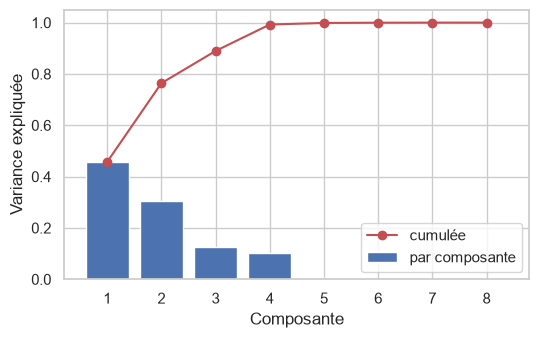

,PC1,PC2
Area,0.37,0.45
Perimeter,0.47,0.26
Major_Axis_Length,0.51,0.10
Minor_Axis_Length,-0.01,0.62
Solidity,0.02,0.16
Extent,-0.18,0.23
Roundness,-0.41,0.36
Aspect_Ration,0.42,-0.35


In [8]:
scaler = StandardScaler()
X = scaler.fit_transform(df_sel)
X_df = pd.DataFrame(X, columns=df_sel.columns)

pca = PCA().fit(X)
plt.figure(figsize=(6, 3.5))
plt.bar(range(1, len(df_sel.columns) + 1), pca.explained_variance_ratio_, label="par composante")
plt.plot(range(1, len(df_sel.columns) + 1), np.cumsum(pca.explained_variance_ratio_), "ro-", label="cumulée")
plt.xlabel("Composante"); plt.ylabel("Variance expliquée"); plt.legend(); plt.show()

pca2 = PCA(n_components=2).fit(X)
Z = pca2.transform(X)   # uniquement pour visualiser les partitions
loadings = pd.DataFrame(pca2.components_.T, index=df_sel.columns, columns=["PC1", "PC2"])
display(loadings.round(2))

**Lecture de l'ACP (utilisée ici uniquement pour explorer et visualiser).**
- Les deux premières composantes résument environ **76 %** de la variance, quatre composantes environ **99 %** : les 8 variables contiennent en réalité environ 4 informations indépendantes.
- **PC1** oppose les graines longues et à grand périmètre (`Major_Axis_Length`, `Perimeter`, `Aspect_Ration`) aux graines arrondies (`Roundness` négatif) : c'est surtout un axe « **allongement / grande longueur** ».
- **PC2** est portée par `Minor_Axis_Length` et `Area` : c'est un axe « **largeur / volume** ».

Les clusters seront visualisés dans ce plan (PC1, PC2), mais **calculés sur les 8 variables standardisées**.

In [9]:
assert list(X_df.columns) == list(df_sel.columns)
assert X_df.shape == (len(df_sel), len(df_sel.columns))
X_df.to_csv("pumpkin_preprocessed_8.csv", index=False)
df_sel.to_csv("pumpkin_selected_8_raw.csv", index=False)
print("Les données standardisées (8 variables) et la sélection principale ont été exportées.")

Les données standardisées (8 variables) et la sélection principale ont été exportées.


#### B.6 Comparaison des sélections de variables

Cette étape répond directement à la question de départ. Pour que la comparaison soit équitable, chaque sélection est standardisée séparément, puis les trois méthodes du projet sont appliquées avec `k = 2` (K-means, Ward et clustering spectral sur un graphe de 30 voisins ; ces méthodes sont détaillées dans la partie II). Les valeurs de silhouette et de Calinski-Harabasz ne sont pas interprétées seules : un score légèrement meilleur ne justifie pas forcément une sélection beaucoup plus difficile à expliquer.

,Sélection,Méthode,Silhouette,Calinski-Harabasz,Taille du plus petit groupe (%)
0,12 variables,K-means,0.308,1212.8,41.7
1,12 variables,Ward,0.238,896.3,44.3
2,12 variables,Spectral kNN,0.296,1174.6,47.8
3,8 variables,K-means,0.306,1106.5,38.0
4,8 variables,Ward,0.231,810.2,47.8
5,8 variables,Spectral kNN,0.282,1056.0,47.3


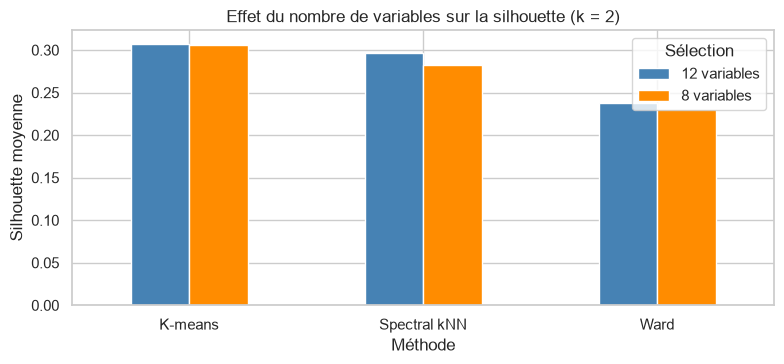

Dans la suite, les analyses détaillées utilisent les 8 variables : c'est le compromis retenu entre information, redondance et lisibilité.


In [10]:
feature_sets = {
    "12 variables": list(df.columns),
    "8 variables": list(df_sel.columns),
}

X_by_set = {name: StandardScaler().fit_transform(df[cols]) for name, cols in feature_sets.items()}

# On conserve les deux versions dans des fichiers distincts pour rendre la comparaison reproductible.
for set_name, cols in feature_sets.items():
    suffix = set_name.split()[0]
    pd.DataFrame(X_by_set[set_name], columns=cols).to_csv(f"pumpkin_preprocessed_{suffix}.csv", index=False)
    df[cols].to_csv(f"pumpkin_selected_{suffix}_raw.csv", index=False)

comparison_rows = []
labels_by_set = {}
for set_name, X_current in X_by_set.items():
    models = {
        "K-means": KMeans(n_clusters=2, n_init=20, random_state=RS),
        "Ward": AgglomerativeClustering(n_clusters=2, linkage="ward"),
        "Spectral kNN": SpectralClustering(n_clusters=2, affinity="nearest_neighbors",
                                           n_neighbors=30, random_state=RS),
    }
    labels_by_set[set_name] = {}
    for method_name, model in models.items():
        labels = model.fit_predict(X_current)
        labels_by_set[set_name][method_name] = labels
        comparison_rows.append({
            "Sélection": set_name,
            "Méthode": method_name,
            "Silhouette": silhouette_score(X_current, labels),
            "Calinski-Harabasz": calinski_harabasz_score(X_current, labels),
            "Taille du plus petit groupe (%)": 100 * np.bincount(labels).min() / len(labels),
        })

comparison = pd.DataFrame(comparison_rows)
display(comparison.style.format({"Silhouette": "{:.3f}", "Calinski-Harabasz": "{:.1f}",
                                 "Taille du plus petit groupe (%)": "{:.1f}"}))

ax = comparison.pivot(index="Méthode", columns="Sélection", values="Silhouette").plot(
    kind="bar", figsize=(8, 3.8), color=["steelblue", "darkorange"])
ax.set_ylabel("Silhouette moyenne")
ax.set_title("Effet du nombre de variables sur la silhouette (k = 2)")
plt.xticks(rotation=0); plt.tight_layout(); plt.show()

print("Dans la suite, les analyses détaillées utilisent les 8 variables : c'est le compromis retenu "
      "entre information, redondance et lisibilité.")

**Lecture.** Pour chacune des trois méthodes, les scores obtenus avec 12 et avec 8 variables sont proches (silhouette de K-means : 0,308 contre 0,306 ; de Ward : 0,238 contre 0,231 ; du spectral : 0,296 contre 0,282) et les groupes restent équilibrés. Retirer les quatre variables redondantes ne dégrade donc pas les résultats et simplifie la description : les **8 variables** sont retenues pour l'analyse détaillée, et la version à 12 variables sert de **test de sensibilité**.

## **<font color='#2E5A7A'>II. Application des méthodes</font>**

- <font color='steelblue'>Appliquez les méthodes de clustering (K-means, clustering hierarchique, clustering spectral).</font>
- <font color='steelblue'>Pour ces parties, vous pouvez vous référer (sans vous limiter) aux notebooks d'aide du TD1, TD2 et TD3:</font><font color='red'> help_kmeans.ipynb, help_hierarchical.ipynb et help_spectral.ipynb.</font>
- <font color='steelblue'>N'hésitez pas à tester différents paramètres (nombre de clusters, nombre d'itérations maximal, méthode de lien "linkage", ...) .</font>
- <font color='steelblue'>Explorez les résultats obtenus.</font>
- <font color='steelblue'>Comparez les résultats obtenus avec les différentes méthodes et choisissez  celle(s) qui vous parait la plus pertinente.</font>
- <font color='steelblue'>Quelles connaissances cette analyse nous permet-elle d'acquérir sur le domaine ?</font>

#### Cadre commun aux trois méthodes

Pour que la comparaison soit équitable, les trois méthodes sont appliquées **sur les mêmes données** (8 variables standardisées, avec les 12 variables en test de sensibilité) et jugées **avec les mêmes outils, sans aucune étiquette connue** :

- la **silhouette** : pour chaque graine, elle compare sa proximité à son propre groupe et au groupe le plus proche (proche de 1 : bien classée ; proche de 0 : entre deux groupes ; négative : peut-être mal classée) ;
- l'**indice de Calinski-Harabasz** : rapport entre la dispersion *entre* les groupes et la dispersion *à l'intérieur* des groupes (plus il est élevé, mieux les groupes sont séparés) ;
- la **taille des groupes**, pour repérer les groupes réduits à quelques graines : une silhouette élevée n'a de sens que si les groupes ont une taille raisonnable ;
- l'**interprétation des profils** : les moyennes des variables d'origine dans chaque groupe ;
- l'**ARI** (indice de Rand ajusté), qui mesure l'accord entre deux partitions : 1 si elles sont identiques, 0 si l'accord est celui du hasard ;
- la **stabilité** : on relance la méthode sur des sous-échantillons et on regarde si la partition se reproduit.

Les clusters sont **calculés sur les variables standardisées** et seulement **dessinés** dans le plan de l'ACP (PC1, PC2).

In [11]:
# Matrices de travail : brutes (pour interpréter) et standardisées (pour calculer)
X_raw = {"12": df, "8": df_sel}
X_std = {n: pd.DataFrame(X_by_set[f"{n} variables"], columns=X_raw[n].columns) for n in X_raw}

# ACP en 2 dimensions pour chaque sélection : uniquement pour dessiner les groupes
acp = {n: PCA(n_components=2).fit(X_std[n]) for n in X_std}
Zn = {n: acp[n].transform(X_std[n]) for n in X_std}

def plot_pca(n, labels, title, ax):
    """Nuage de points dans le plan (PC1, PC2), coloré par groupe."""
    ax.scatter(Zn[n][:, 0], Zn[n][:, 1], c=labels, cmap="tab10", s=8, alpha=0.7)
    ax.set_xlabel(f"PC1 ({acp[n].explained_variance_ratio_[0]:.0%})")
    ax.set_ylabel(f"PC2 ({acp[n].explained_variance_ratio_[1]:.0%})")
    ax.set_title(title)

def profile(n, labels):
    """Profil des groupes : écarts à la moyenne (en écarts-types), puis moyennes en unités d'origine."""
    sizes = pd.Series(labels).value_counts().sort_index()
    zs = X_std[n].groupby(labels).mean().T
    plt.figure(figsize=(1.6 * zs.shape[1] + 3, 0.45 * zs.shape[0] + 1.5))
    sns.heatmap(zs, annot=True, fmt=".2f", cmap="coolwarm", center=0)
    plt.title("Profil des groupes (écart à la moyenne, en écarts-types)")
    plt.show()
    display(X_raw[n].groupby(labels).mean().T.round(2)
            .rename(columns=lambda c: f"groupe {c} (n={sizes[c]})"))

def aligner(lab, ref):
    """Les numéros de groupe sont arbitraires : on les aligne sur une partition de référence (k = 2)."""
    return 1 - lab if (lab == ref).mean() < 0.5 else lab

### <font color='#2E5A7A'>1. K-means</font>

K-means cherche une partition en `k` groupes qui **minimise la dispersion des graines autour du centre de leur groupe** (l'*inertie*). À chaque étape, chaque graine est rattachée au centre le plus proche, puis chaque centre est recalculé comme la moyenne de son groupe, jusqu'à stabilisation.

Trois choses sont à retenir pour la suite :

- le nombre de groupes `k` **doit être choisi** par l'analyste ; l'inertie diminue mécaniquement quand `k` augmente, elle ne suffit donc pas à choisir ;
- le résultat dépend de l'**initialisation** des centres : nous utilisons plusieurs initialisations (`n_init=20`) et une graine fixée (`random_state=0`) pour obtenir un résultat reproductible ;
- K-means favorise des groupes **compacts, de forme arrondie et de taille comparable**.

#### 1.1 Premier essai : paramètres par défaut

Paramètres par défaut : {'init': 'k-means++', 'max_iter': 300, 'n_clusters': 8, 'n_init': 'auto'}
Taille des groupes : [357 224 444 370 187 234 478 206]


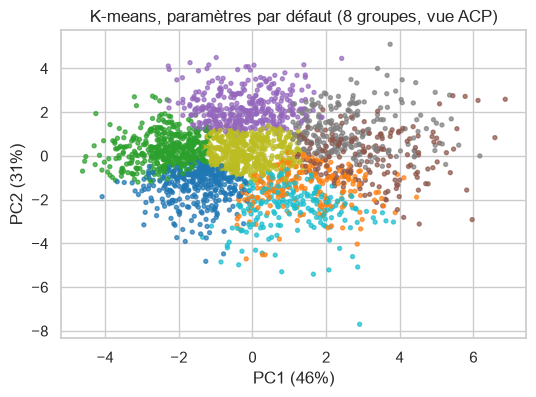

In [12]:
km_defaut = KMeans(random_state=RS)
print("Paramètres par défaut :", {p: v for p, v in km_defaut.get_params().items()
                                  if p in ("n_clusters", "init", "n_init", "max_iter")})
km_defaut.fit(X_std["8"])
print("Taille des groupes :", np.bincount(km_defaut.labels_))

fig, ax = plt.subplots(figsize=(6, 4))
plot_pca("8", km_defaut.labels_, "K-means, paramètres par défaut (8 groupes, vue ACP)", ax)
plt.show()

**Lecture.** Par défaut, `scikit-learn` demande **8 groupes**, un nombre qui n'a aucune raison d'être le bon pour nos graines. Le résultat découpe le nuage en petites tranches qui se recouvrent largement dans la vue ACP : il n'est pas interprétable tel quel. Le premier travail consiste donc à **choisir `k`** de manière argumentée.

#### 1.2 Choix du nombre de groupes

Pour `k` de 2 à 10 et pour chaque sélection de variables, nous relevons quatre indicateurs : l'**inertie** (méthode du coude), la **silhouette**, l'indice de **Calinski-Harabasz** et la **taille du plus petit groupe**.

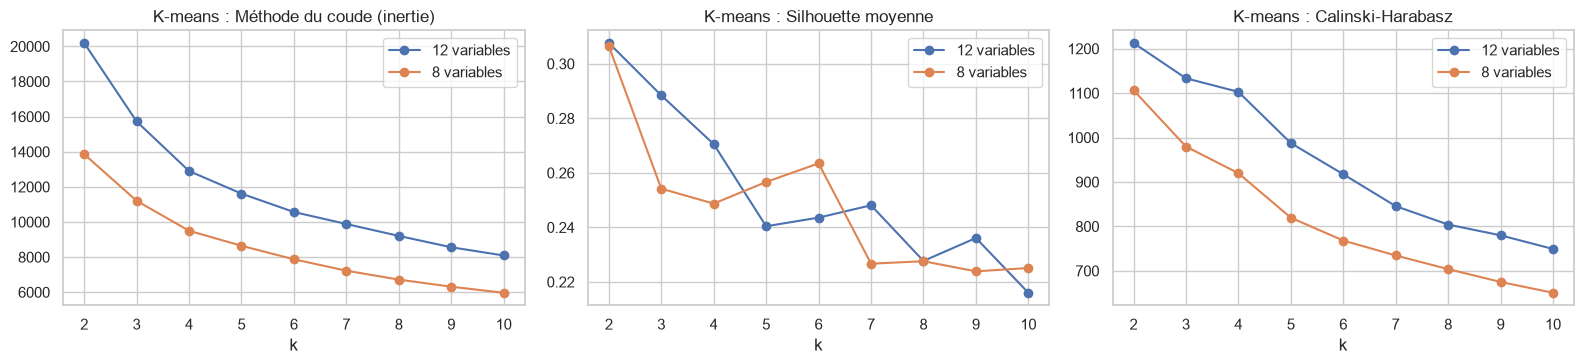

inertie            silhouette        Calinski-Harabasz           plus petit groupe       
variables         12          8         12      8                12         8                12      8
k                                                                                                     
2          20194.909  13860.570      0.308  0.306          1212.838  1106.473            1042.0  949.0
3          15725.192  11206.047      0.288  0.254          1133.347   979.761             679.0  692.0
4          12900.394   9499.298      0.271  0.249          1102.825   919.708             468.0  430.0
5          11613.721   8643.433      0.240  0.257           987.497   819.542             378.0  315.0
6          10566.516   7873.575      0.244  0.263           917.373   768.225             276.0   38.0
7           9884.031   7225.782      0.248  0.227           845.625   734.554              32.0   30.0
8           9205.893   6717.677      0.228  0.228           804.126   703.890              26.0   28.0
9           8559.613   6313.375      0.236  0.224           779.942   675.023              26.0   47.0
10          8090.578   5967.285      0.216  0.225           749.218   650.614              18.0   10.0

In [13]:
ks = range(2, 11)
km_rows = []
for n in X_std:
    for k in ks:
        model = KMeans(n_clusters=k, n_init=20, random_state=RS)
        lab = model.fit_predict(X_std[n])
        km_rows.append({
            "variables": n, "k": k,
            "inertie": model.inertia_,
            "silhouette": silhouette_score(X_std[n], lab),
            "Calinski-Harabasz": calinski_harabasz_score(X_std[n], lab),
            "plus petit groupe": np.bincount(lab).min(),
        })
km_scan = pd.DataFrame(km_rows)

fig, ax = plt.subplots(1, 3, figsize=(16, 3.8))
for n in X_std:
    d = km_scan[km_scan["variables"] == n]
    ax[0].plot(d["k"], d["inertie"], "o-", label=f"{n} variables")
    ax[1].plot(d["k"], d["silhouette"], "o-", label=f"{n} variables")
    ax[2].plot(d["k"], d["Calinski-Harabasz"], "o-", label=f"{n} variables")
for a, t in zip(ax, ["Méthode du coude (inertie)", "Silhouette moyenne", "Calinski-Harabasz"]):
    a.set_title(f"K-means : {t}"); a.set_xlabel("k"); a.legend()
plt.tight_layout(); plt.show()

display(km_scan.pivot(index="k", columns="variables",
                      values=["inertie", "silhouette", "Calinski-Harabasz", "plus petit groupe"]).round(3))

**Choix de `k`.** Avec 8 variables, l'inertie baisse régulièrement (de 13 861 pour `k = 2` à 5 967 pour `k = 10`) **sans coude net** : la méthode du coude ne permet pas de trancher. La **silhouette est maximale pour `k = 2`** (0,306), de même que l'indice de Calinski-Harabasz (1 106, qui décroît ensuite jusqu'à 651). Avec 12 variables, la silhouette est également maximale pour `k = 2` (0,308). La légère remontée de la silhouette pour `k = 5` et `k = 6` avec 8 variables (0,257 et 0,263, toujours sous 0,306) ne justifie pas ces découpages : à `k = 6`, le plus petit groupe ne contient que 38 graines.

Nous retenons **`k = 2` comme résultat principal** et **`k = 3` comme lecture complémentaire** (silhouette de 0,254, plus faible mais avec des groupes d'effectifs comparables, entre 692 et 1 080 graines).

#### 1.3 Résultat de K-means avec k = 2 (8 variables)

Effectifs K-means : [1551  949]
Silhouette : 0.306
Calinski-Harabasz : 1106.5
Graines avec une silhouette négative : 100 sur 2500


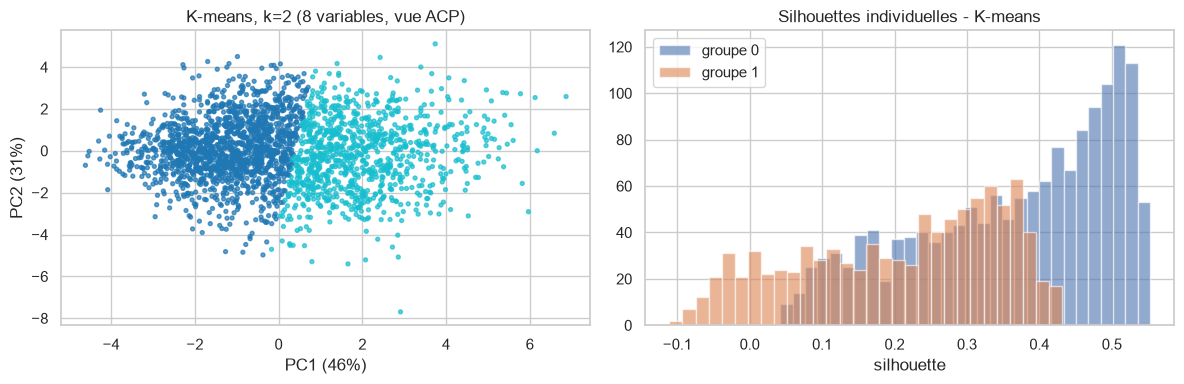

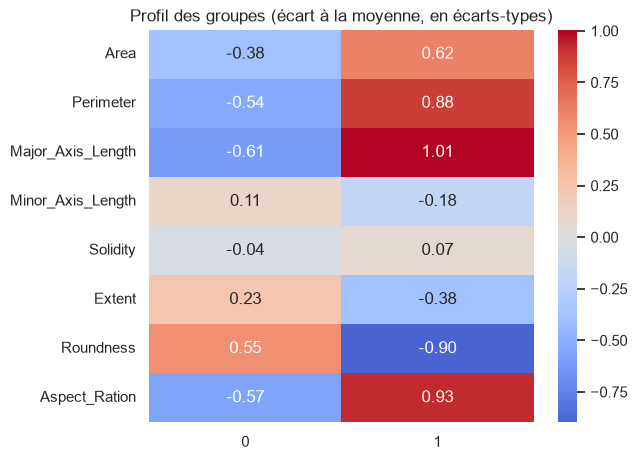

,groupe 0 (n=1551),groupe 1 (n=949)
Area,75491.29,89102.80
Perimeter,1071.74,1225.96
Major_Axis_Length,422.03,513.11
Minor_Axis_Length,228.36,221.60
Solidity,0.99,0.99
Extent,0.71,0.67
Roundness,0.82,0.74
Aspect_Ration,1.86,2.34


In [14]:
kmeans2 = KMeans(n_clusters=2, n_init=20, random_state=RS)
labels_kmeans = kmeans2.fit_predict(X_std["8"])
print("Effectifs K-means :", np.bincount(labels_kmeans))
print("Silhouette :", round(silhouette_score(X_std["8"], labels_kmeans), 3))
print("Calinski-Harabasz :", round(calinski_harabasz_score(X_std["8"], labels_kmeans), 1))

sil_km = silhouette_samples(X_std["8"], labels_kmeans)
print("Graines avec une silhouette négative :", (sil_km < 0).sum(), "sur", len(sil_km))

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
plot_pca("8", labels_kmeans, "K-means, k=2 (8 variables, vue ACP)", ax[0])
for c in range(2):
    ax[1].hist(sil_km[labels_kmeans == c], bins=30, alpha=0.6, label=f"groupe {c}")
ax[1].set_title("Silhouettes individuelles - K-means")
ax[1].set_xlabel("silhouette"); ax[1].legend()
plt.tight_layout(); plt.show()

profile("8", labels_kmeans)

**Résultat de K-means, k = 2, 8 variables.** K-means sépare le lot en deux profils :

- un groupe de graines **plus petites, plus courtes et plus arrondies** (1 551 graines, soit 62 % du lot) : aire ≈ 75 500, longueur ≈ 422, rapport longueur/largeur ≈ 1,86, rondeur ≈ 0,82 ;
- un groupe de graines **plus grandes, plus longues et plus allongées** (949 graines, soit 38 %) : aire ≈ 89 100, longueur ≈ 513, rapport ≈ 2,34, rondeur ≈ 0,74.

Un détail important : la **largeur** (`Minor_Axis_Length`) est presque la même dans les deux groupes (≈ 228 contre ≈ 222). Ce qui différencie les groupes est donc surtout la **longueur** de la graine (et par conséquent son périmètre, son aire et son allongement), pas sa largeur. `Solidity` et `Extent` varient très peu entre les groupes. Les histogrammes de silhouettes individuelles montrent que le nombre de graines mal classées (silhouette négative, affiché ci-dessus) n'est pas négligeable : les deux nuages se recouvrent dans la vue ACP, sans vide entre eux. La silhouette de 0,31 correspond à une structure **réelle mais modérée**.

#### 1.4 Une lecture plus fine : k = 3 (8 variables)

Effectifs K-means k=3 : [ 692  728 1080]
Silhouette k=3 : 0.254


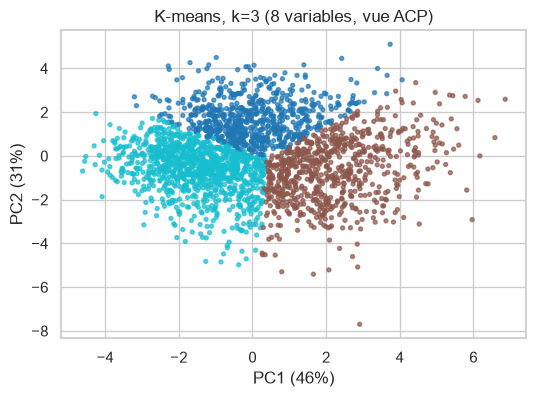

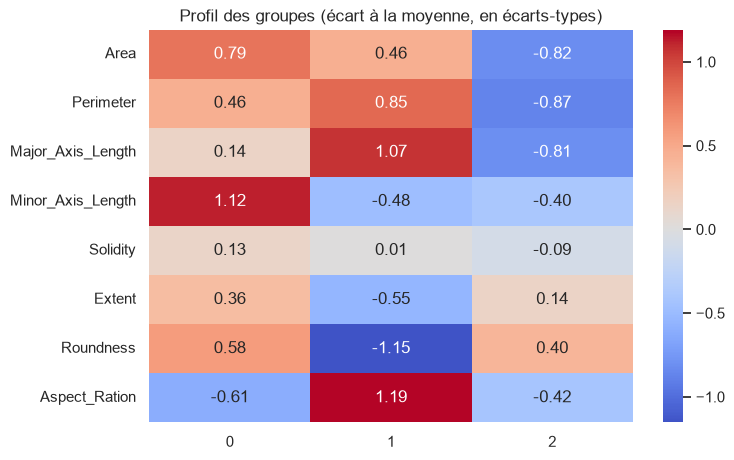

,groupe 0 (n=692),groupe 1 (n=728),groupe 2 (n=1080)
Area,91516.82,86965.60,69449.03
Perimeter,1180.92,1223.40,1035.06
Major_Axis_Length,464.66,516.78,410.87
Minor_Axis_Length,251.98,214.63,216.54
Solidity,0.99,0.99,0.99
Extent,0.71,0.66,0.70
Roundness,0.82,0.73,0.81
Aspect_Ration,1.85,2.42,1.91


In [15]:
kmeans3 = KMeans(n_clusters=3, n_init=20, random_state=RS).fit(X_std["8"])
labels_kmeans3 = kmeans3.labels_
print("Effectifs K-means k=3 :", np.bincount(labels_kmeans3))
print("Silhouette k=3 :", round(silhouette_score(X_std["8"], labels_kmeans3), 3))

fig, ax = plt.subplots(figsize=(6, 4))
plot_pca("8", labels_kmeans3, "K-means, k=3 (8 variables, vue ACP)", ax)
plt.show()
profile("8", labels_kmeans3)

**Lecture avec k = 3.** K-means distingue trois profils d'effectifs comparables :

- des graines **petites** (1 080 graines : aire ≈ 69 400, longueur ≈ 411) ;
- des graines **grandes et larges** (692 graines : aire ≈ 91 500, largeur ≈ 252, rapport ≈ 1,85) ;
- des graines **longues et étroites** (728 graines : longueur ≈ 517, largeur ≈ 215, rapport ≈ 2,42, rondeur ≈ 0,73).

Le découpage en trois fait apparaître une **dimension de taille** que `k = 2` ne montrait pas : parmi les graines peu allongées, il y a des petites et des grandes. Cette partition est plus riche mais **moins nette** (silhouette de 0,254 contre 0,306) : nous la présentons comme une lecture complémentaire, pas comme le résultat principal.

### <font color='#2E5A7A'>2. Clustering hiérarchique</font>

Le clustering hiérarchique ascendant commence avec une graine par groupe, puis fusionne à chaque étape les deux groupes les plus proches. Ce que « proche » veut dire dépend du **lien** (*linkage*) : `single` (plus petite distance entre deux groupes), `complete` (plus grande distance), `average` (distance moyenne) ou `ward` (fusion qui augmente le moins possible la variance à l'intérieur des groupes). Le **dendrogramme** garde la trace de toutes les fusions, et couper l'arbre à une certaine hauteur fournit un nombre de groupes `k`.

Contrairement à K-means, il n'y a **pas d'initialisation aléatoire** : le résultat est déterministe pour un lien et un `k` donnés. En revanche, il est très sensible au choix du lien.

Deux sélections de variables sont comparées : **12 variables** et **8 variables**.

#### 2.1 Premier essai : lien `complete`, paramètres par défaut

In [16]:
hclust = AgglomerativeClustering(linkage="complete")
hclust.get_params()

{'compute_distances': False,
 'compute_full_tree': 'auto',
 'connectivity': None,
 'distance_threshold': None,
 'linkage': 'complete',
 'memory': None,
 'metric': 'euclidean',
 'n_clusters': 2}

In [17]:
hclust.fit(X_std["8"])
print(hclust.labels_[:20])
print("Taille des groupes :", np.bincount(hclust.labels_))

[0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0]
Taille des groupes : [2499    1]


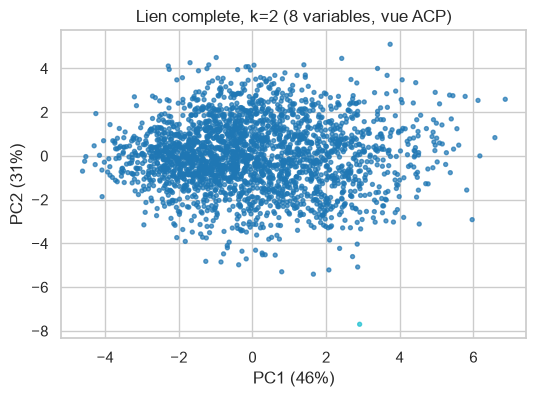

In [18]:
fig, ax = plt.subplots(figsize=(6, 4))
plot_pca("8", hclust.labels_, "Lien complete, k=2 (8 variables, vue ACP)", ax)
plt.show()

**Lecture.** Avec les paramètres par défaut (2 groupes, lien `complete`), l'un des deux groupes ne contient qu'**une seule graine** : l'algorithme isole une valeur extrême au lieu de séparer le lot en deux profils. Ce n'est pas un résultat exploitable, ce qui justifie de comparer les liens.

#### 2.2 Comparaison des liens

Pour chaque lien et pour `k` de 2 à 6, nous relevons la silhouette et la taille du plus petit groupe. Cette seconde mesure est indispensable : une silhouette élevée n'a de sens que si les groupes ont une taille raisonnable.

In [19]:
rows = []
for n in X_std:
    for link in ["ward", "complete", "average", "single"]:
        for k in range(2, 7):
            lab = AgglomerativeClustering(n_clusters=k, linkage=link).fit_predict(X_std[n])
            rows.append({"variables": n, "lien": link, "k": k,
                         "silhouette": silhouette_score(X_std[n], lab),
                         "plus petit groupe": np.bincount(lab).min()})
liens = pd.DataFrame(rows)

for n in X_std:
    d = liens[liens["variables"] == n]
    print("---", n, "variables : silhouette ---")
    display(d.pivot(index="lien", columns="k", values="silhouette").round(3))
    print("---", n, "variables : taille du plus petit groupe (graines) ---")
    display(d.pivot(index="lien", columns="k", values="plus petit groupe"))

--- 12 variables : silhouette ---


k,2,3,4,5,6
lien,,,,,
average,0.794,0.582,0.534,0.389,0.342
complete,0.731,0.254,0.246,0.166,0.172
single,0.794,0.582,0.549,0.542,0.477
ward,0.238,0.224,0.203,0.186,0.191


--- 12 variables : taille du plus petit groupe (graines) ---


k,2,3,4,5,6
lien,,,,,
average,1,1,1,1,1
complete,2,2,2,2,2
single,1,1,1,1,1
ward,1108,524,524,312,27


--- 8 variables : silhouette ---


k,2,3,4,5,6
lien,,,,,
average,0.829,0.558,0.387,0.377,0.347
complete,0.829,0.564,0.307,0.161,0.161
single,0.829,0.665,0.553,0.554,0.532
ward,0.231,0.198,0.180,0.198,0.211


--- 8 variables : taille du plus petit groupe (graines) ---


k,2,3,4,5,6
lien,,,,,
average,1,1,1,1,1
complete,1,1,1,1,1
single,1,1,1,1,1
ward,1194,312,312,312,51


**Piège à éviter.** Les liens `single`, `complete` et `average` donnent des silhouettes très élevées pour `k = 2` (environ 0,83 avec 8 variables et 0,73 à 0,79 avec 12), mais le second tableau montre que leur plus petit groupe ne contient que **1 à 2 graines** : ils isolent une graine extrême et mettent les autres dans un seul bloc. C'est la sensibilité aux valeurs extrêmes, que nous avions choisi de conserver car elles sont plausibles. **Ces silhouettes ne reflètent pas une vraie structure et ne sont pas exploitables.**

Seul le lien de **Ward** donne des groupes équilibrés (le plus petit groupe représente 44 % à 48 % du lot pour `k = 2`). Sa silhouette est plus modeste (≈ 0,23), ce qui est normal : elle n'est pas gonflée par des groupes réduits à une graine. **Nous retenons Ward pour la suite.**

#### 2.3 Dendrogramme (Ward) et choix du nombre de groupes

12 variables - 8 dernières hauteurs de fusion : [ 37.4  39.2  39.4  40.4  55.3  77.3  95.5 125.9]
8 variables - 8 dernières hauteurs de fusion : [28.2 31.6 32.4 43.6 49.  62.3 65.3 99. ]


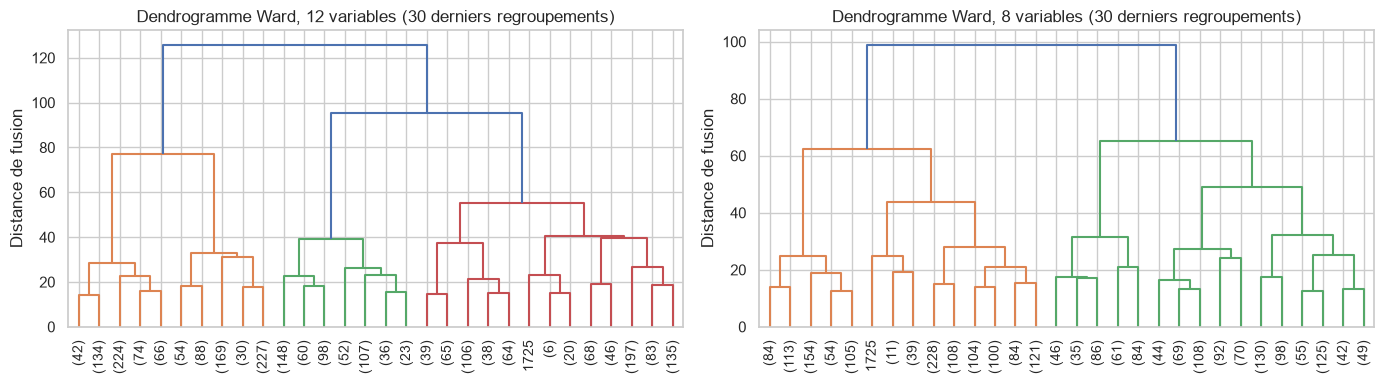

In [20]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
for a, n in zip(ax, X_std):
    Zw = linkage(X_std[n], method="ward")
    dendrogram(Zw, truncate_mode="lastp", p=30, show_leaf_counts=True, leaf_rotation=90, ax=a)
    a.set_title(f"Dendrogramme Ward, {n} variables (30 derniers regroupements)")
    a.set_ylabel("Distance de fusion")
    print(n, "variables - 8 dernières hauteurs de fusion :", Zw[-8:, 2].round(1))
plt.tight_layout()
plt.show()

**Lecture du dendrogramme.** La dernière fusion, celle qui réunit les deux grands groupes, est nettement plus haute que la précédente : environ 99 contre 65 avec 8 variables, et 126 contre 96 avec 12 variables. Couper l'arbre en **deux groupes** est donc le découpage le plus naturel. Au-delà, les hauteurs de fusion décroissent progressivement (avec 8 variables : 65, 62, 49, 44), sans seconde rupture aussi nette : la structure en plus de deux groupes ressemble davantage à un continuum qu'à des blocs séparés.

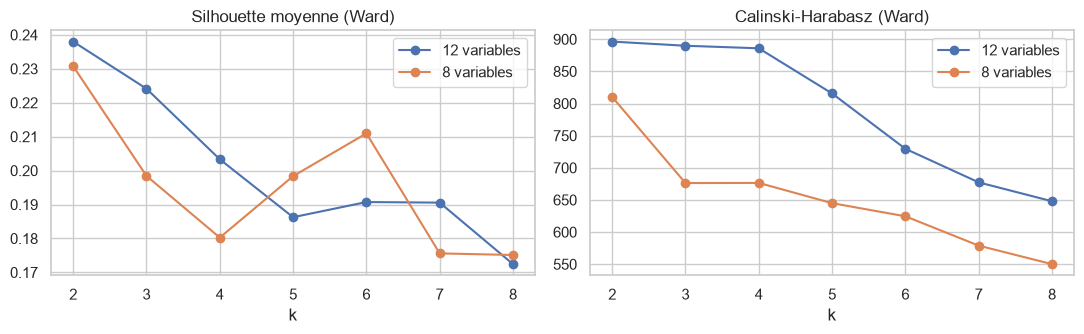

silhouette        Calinski-Harabasz          plus petit groupe        
variables         12      8                12        8                12       8
k                                                                               
2              0.238  0.231           896.319  810.184            1108.0  1194.0
3              0.224  0.198           889.858  676.261             524.0   312.0
4              0.203  0.180           885.884  676.472             524.0   312.0
5              0.186  0.198           815.612  644.962             312.0   312.0
6              0.191  0.211           729.524  624.550              27.0    51.0
7              0.191  0.176           677.315  578.891              27.0    51.0
8              0.172  0.175           647.940  550.098              27.0    51.0

In [21]:
crit = []
for n in X_std:
    for k in range(2, 9):
        lab = AgglomerativeClustering(n_clusters=k, linkage="ward").fit_predict(X_std[n])
        crit.append({"variables": n, "k": k,
                     "silhouette": silhouette_score(X_std[n], lab),
                     "Calinski-Harabasz": calinski_harabasz_score(X_std[n], lab),
                     "plus petit groupe": np.bincount(lab).min()})
crit = pd.DataFrame(crit)

fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
for n in X_std:
    d = crit[crit["variables"] == n]
    ax[0].plot(d["k"], d["silhouette"], "o-", label=f"{n} variables")
    ax[1].plot(d["k"], d["Calinski-Harabasz"], "o-", label=f"{n} variables")
ax[0].set_title("Silhouette moyenne (Ward)")
ax[1].set_title("Calinski-Harabasz (Ward)")
for a in ax:
    a.set_xlabel("k")
    a.legend()
plt.tight_layout()
plt.show()

display(crit.pivot(index="k", columns="variables",
                   values=["silhouette", "Calinski-Harabasz", "plus petit groupe"]).round(3))

**Choix de `k`.** Avec les deux sélections de variables, la silhouette et l'indice de Calinski-Harabasz sont les plus élevés pour `k = 2`, puis diminuent. La légère remontée de la silhouette à `k = 6` avec 8 variables s'explique par un petit groupe de 51 graines (2 % du lot) et ne justifie pas ce découpage. Dendrogramme, silhouette et Calinski-Harabasz convergent : nous retenons **`k = 2` comme résultat principal** et `k = 3` comme lecture complémentaire.

#### 2.4 Résultat de Ward avec k = 2

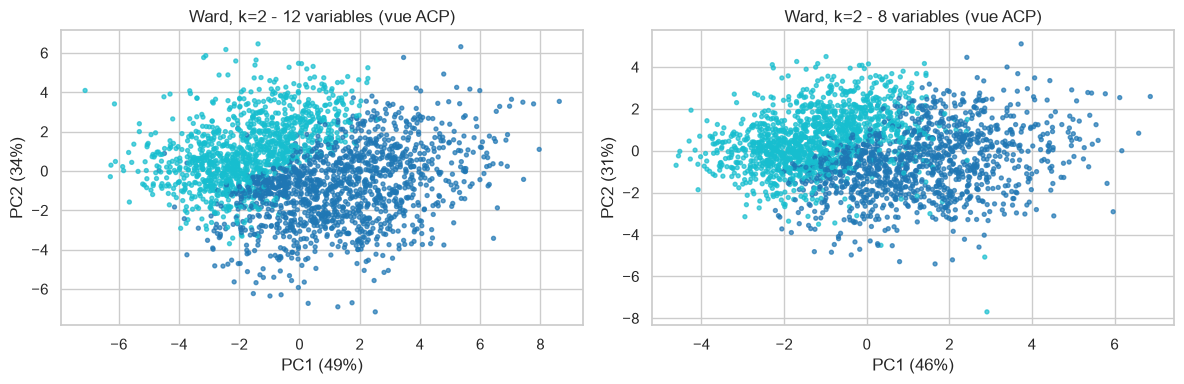

12 variables - silhouette : 0.238 | Calinski-Harabasz : 896.3 | tailles : [1392 1108]
8 variables - silhouette : 0.231 | Calinski-Harabasz : 810.2 | tailles : [1194 1306]


In [22]:
ward = {n: AgglomerativeClustering(n_clusters=2, linkage="ward").fit(X_std[n]) for n in X_std}

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for a, n in zip(ax, X_std):
    plot_pca(n, ward[n].labels_, f"Ward, k=2 - {n} variables (vue ACP)", a)
plt.tight_layout()
plt.show()

for n in X_std:
    lab = ward[n].labels_
    print(n, "variables - silhouette :", round(silhouette_score(X_std[n], lab), 3),
          "| Calinski-Harabasz :", round(calinski_harabasz_score(X_std[n], lab), 1),
          "| tailles :", np.bincount(lab))

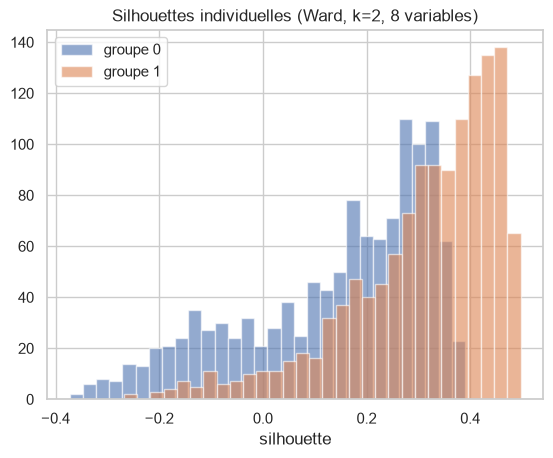

Graines avec une silhouette négative : 339 sur 2500


In [23]:
lab = ward["8"].labels_
s = silhouette_samples(X_std["8"], lab)
for c in range(2):
    plt.hist(s[lab == c], bins=30, alpha=0.6, label=f"groupe {c}")
plt.title("Silhouettes individuelles (Ward, k=2, 8 variables)")
plt.xlabel("silhouette")
plt.legend()
plt.show()
print("Graines avec une silhouette négative :", (s < 0).sum(), "sur", len(s))

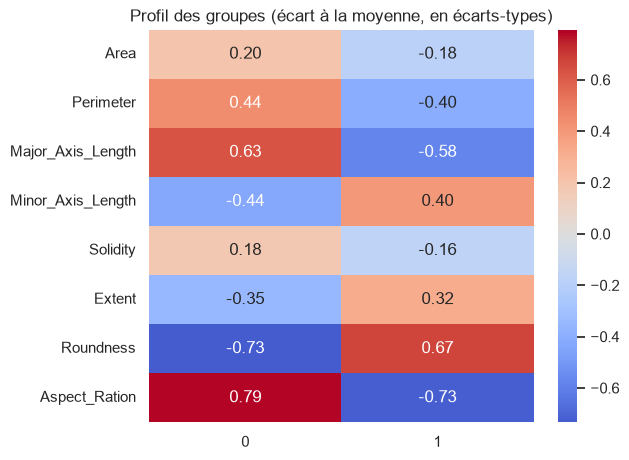

,groupe 0 (n=1194),groupe 1 (n=1306)
Area,83360.65,78187.54
Perimeter,1178.37,1086.31
Major_Axis_Length,492.05,424.20
Minor_Axis_Length,215.66,235.06
Solidity,0.99,0.99
Extent,0.67,0.71
Roundness,0.75,0.83
Aspect_Ration,2.29,1.81


In [24]:
profile("8", ward["8"].labels_)

**Résultat de Ward, k = 2, 8 variables.** Ward sépare le lot selon la **forme** :

- un groupe de graines **allongées** (≈ 48 % du lot) : rapport longueur/largeur d'environ 2,3, longueur d'environ 490, largeur d'environ 216, indice de rondeur d'environ 0,75 ;
- un groupe de graines **plus trapues** (≈ 52 % du lot) : rapport longueur/largeur d'environ 1,8, longueur d'environ 424, largeur d'environ 235, rondeur d'environ 0,83.

Les aires moyennes des deux groupes sont proches (≈ 83 000 contre ≈ 78 000, soit environ 6 % d'écart) : les graines allongées sont un peu plus grandes, mais la **taille n'est pas le critère principal** de séparation. Dans la projection ACP, les deux nuages se chevauchent largement, sans vide entre eux, et environ 14 % des graines (339 sur 2 500) ont une silhouette négative, c'est-à-dire qu'elles sont plus proches de l'autre groupe que du leur : il existe une zone de graines intermédiaires plutôt que deux catégories nettement séparées.

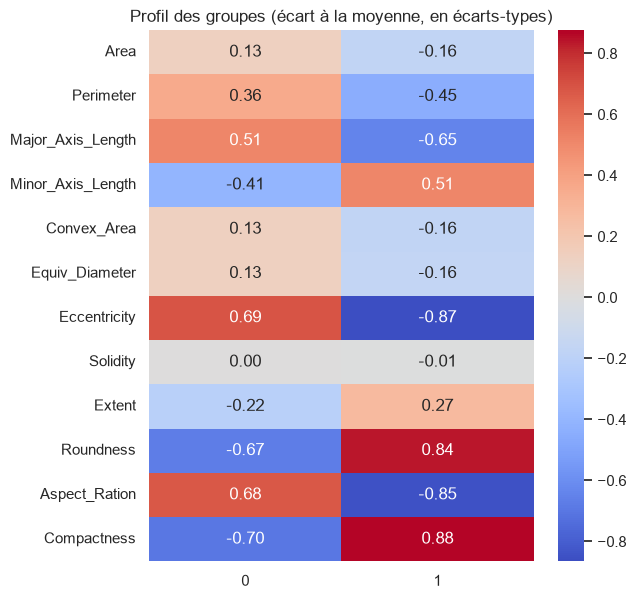

,groupe 0 (n=1392),groupe 1 (n=1108)
Area,82451.43,78405.38
Perimeter,1169.26,1081.31
Major_Axis_Length,485.53,420.25
Minor_Axis_Length,216.33,237.69
Convex_Area,83314.45,79238.72
Equiv_Diameter,322.78,315.01
Eccentricity,0.89,0.82
Solidity,0.99,0.99
Extent,0.68,0.71
Roundness,0.75,0.84


In [25]:
profile("12", ward["12"].labels_)

**Avec 12 variables**, on retrouve les mêmes deux profils (allongées : rapport longueur/largeur ≈ 2,26 ; trapues : ≈ 1,77), mais la frontière se déplace : le groupe allongé représente 56 % du lot au lieu de 48 %.

#### 2.5 Une lecture plus fine : k = 3 (8 variables)

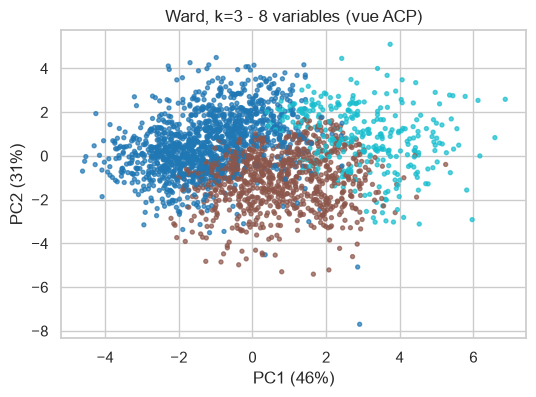

silhouette : 0.198


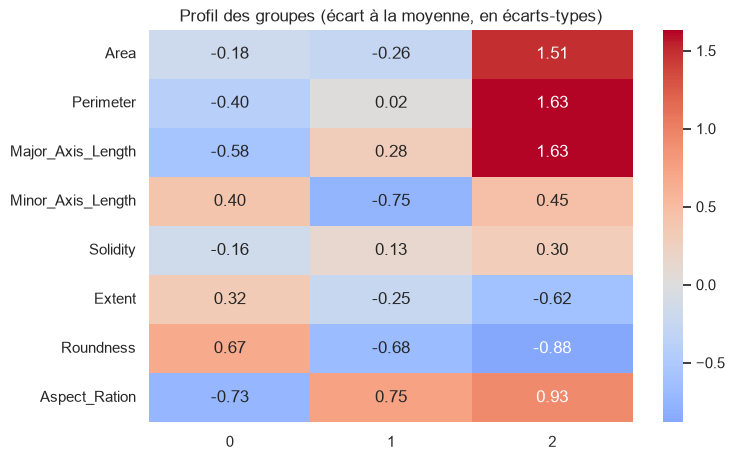

,groupe 0 (n=1306),groupe 1 (n=882),groupe 2 (n=312)
Area,78187.54,77042.20,101222.44
Perimeter,1086.31,1132.27,1308.69
Major_Axis_Length,424.20,472.23,548.07
Minor_Axis_Length,235.06,208.35,236.33
Solidity,0.99,0.99,0.99
Extent,0.71,0.68,0.66
Roundness,0.83,0.75,0.74
Aspect_Ration,1.81,2.28,2.34


In [26]:
ward3 = AgglomerativeClustering(n_clusters=3, linkage="ward").fit(X_std["8"])

fig, ax = plt.subplots(figsize=(6, 4))
plot_pca("8", ward3.labels_, "Ward, k=3 - 8 variables (vue ACP)", ax)
plt.show()

print("silhouette :", round(silhouette_score(X_std["8"], ward3.labels_), 3))
profile("8", ward3.labels_)

**Lecture avec k = 3.** Ward conserve le groupe de graines trapues (≈ 1 300 graines) et **divise le groupe allongé en deux** selon la taille :

- des graines allongées et **étroites** de taille moyenne (≈ 880 graines : aire ≈ 77 000, largeur ≈ 208, rapport ≈ 2,28) ;
- des graines allongées, **longues et grosses** (≈ 310 graines : aire ≈ 101 000, longueur ≈ 548).

Cette partition décrit mieux la diversité de taille parmi les graines allongées, mais sa silhouette est plus faible (≈ 0,20 contre 0,23) et le dendrogramme ne la soutient pas aussi nettement que `k = 2`. Nous la présentons comme une lecture complémentaire.

#### 2.6 Comparaison 12 contre 8 variables

Les deux sélections produisent-elles les mêmes groupes ? Nous comparons les groupes de Ward à `k = 2` graine par graine.

In [27]:
lab12 = aligner(ward["12"].labels_, ward["8"].labels_)
lab8 = ward["8"].labels_

print("Part des graines placées dans le même groupe :", round((lab12 == lab8).mean(), 3))
print("ARI entre les deux partitions :", round(adjusted_rand_score(lab12, lab8), 2))
display(pd.crosstab(lab12, lab8, rownames=["12 variables"], colnames=["8 variables"]))

Part des graines placées dans le même groupe : 0.867
ARI entre les deux partitions : 0.54


8 variables,0,1
12 variables,,
0,1127,265
1,67,1041


Les deux sélections racontent la **même histoire générale** (un profil allongé et un profil trapu), mais environ **13 % des graines (332 sur 2 500) changent de groupe**, et l'indice de Rand ajusté (ARI) n'est que d'environ 0,54. Qui sont ces graines ? Nous les comparons aux autres, avec les valeurs d'origine.

In [28]:
change = lab12 != lab8
print("Nombre de graines qui changent de groupe :", change.sum())
display(X_raw["8"].groupby(change).mean().T.round(2).rename(columns={False: "restent", True: "changent"}))

Nombre de graines qui changent de groupe : 332


,restent,changent
Area,81704.61,73825.16
Perimeter,1137.55,1082.80
Major_Axis_Length,459.99,434.50
Minor_Axis_Length,227.18,216.78
Solidity,0.99,0.99
Extent,0.69,0.70
Roundness,0.79,0.79
Aspect_Ration,2.05,2.01


**Lecture.** Les graines qui changent de groupe ont un rapport longueur/largeur d'environ 2,0, soit à peu près la moyenne du lot (≈ 2,04) et entre celui des deux groupes (≈ 1,8 et ≈ 2,3) : ce sont des graines **intermédiaires**, proches de la frontière. Elles sont aussi un peu plus petites que les autres (aire ≈ 73 800 contre ≈ 81 700). Leur groupe dépend donc de la sélection de variables, alors que les graines clairement allongées ou clairement trapues sont affectées de la même façon dans les deux cas.

Une explication possible est que, avec 12 variables, plusieurs mesures redondantes de taille ou de forme comptent chacune dans la distance, ce qui déplace la frontière. Nous ne l'avons pas testée directement ; ce qui est établi, c'est que les graines concernées sont des graines intermédiaires. Les 8 variables restent préférables, car elles évitent de compter plusieurs fois la même information.

#### 2.7 Bilan du clustering hiérarchique

- Le **lien** est décisif : seul Ward donne des groupes exploitables, les trois autres isolent des graines extrêmes.
- Le **dendrogramme** montre **une division principale** (deux grands groupes) suivie d'un **continuum**, sans seconde rupture nette.
- Ward distingue des graines **allongées** et des graines **trapues**, avec une faible différence de taille : c'est la **forme** qui sépare le lot.
- La frontière est **fragile** : 13 % des graines changent de groupe quand on passe de 8 à 12 variables. La stabilité de Ward sera mesurée en partie 4 et comparée aux deux autres méthodes.

### <font color='#2E5A7A'>3. Clustering spectral</font>

Le clustering spectral ne cherche pas directement des centres. Il procède en trois temps :

1. il construit un **graphe de proximité** entre les graines (deux graines sont reliées si elles se ressemblent) ;
2. il calcule les **vecteurs propres du laplacien** de ce graphe, qui donnent une nouvelle représentation des graines dans laquelle les groupes bien connectés sont faciles à séparer ;
3. il applique **K-means** dans cet espace réduit.

L'intérêt de la méthode est qu'elle repère des groupes **connectés** par le graphe, même s'ils ne sont pas de forme arrondie. Ses réglages principaux sont le **type de graphe** (graphe des `n_neighbors` plus proches voisins, ou noyau gaussien RBF de paramètre `gamma`) et le nombre de groupes `k`. Nous utilisons le graphe des plus proches voisins, plus stable en pratique, et nous testons le noyau RBF à titre de comparaison.

#### 3.1 Le graphe de voisinage et l'*eigengap*

Le spectre du laplacien du graphe donne un indice sur le nombre de groupes : s'il y a `k` groupes bien séparés, les `k` premières valeurs propres sont proches de 0, puis on observe un **saut** (l'*eigengap*). Nous construisons le graphe des 30 plus proches voisins (symétrisé) et nous regardons les 10 plus petites valeurs propres.

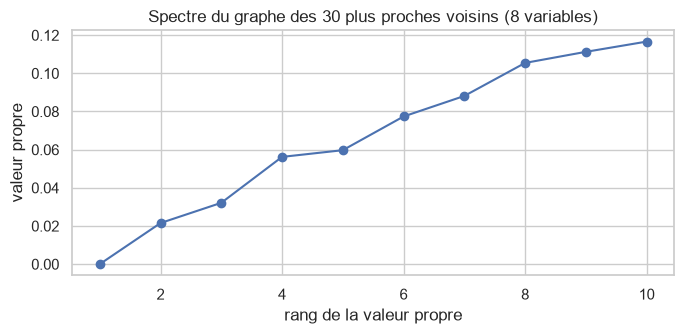

Valeurs propres : [0.    0.022 0.032 0.056 0.06  0.077 0.088 0.105 0.111 0.117]
Écarts successifs : [0.022 0.011 0.024 0.004 0.018 0.011 0.017 0.006 0.005]


In [29]:
A = kneighbors_graph(X_std["8"], 30, include_self=False)
A = 0.5 * (A + A.T)
eigenvalues = np.linalg.eigvalsh(laplacian(A, normed=True).toarray())[:10]

plt.figure(figsize=(7, 3.5))
plt.plot(range(1, 11), eigenvalues, "o-")
plt.xlabel("rang de la valeur propre"); plt.ylabel("valeur propre")
plt.title("Spectre du graphe des 30 plus proches voisins (8 variables)")
plt.tight_layout(); plt.show()
print("Valeurs propres :", np.round(eigenvalues, 3))
print("Écarts successifs :", np.round(np.diff(eigenvalues), 3))

**Lecture.** Une seule valeur propre est nulle : le graphe est **connexe** (d'un seul tenant). Les valeurs suivantes (≈ 0,022 ; 0,032 ; 0,056 ; 0,060 ; 0,077…) augmentent **progressivement**, sans saut net qui désignerait un nombre de groupes évident. Cela rejoint ce que montrait le dendrogramme : il n'existe pas de blocs nettement séparés, mais un continuum. L'*eigengap* ne suffit donc pas à choisir `k` ; nous nous appuyons aussi sur la silhouette, l'équilibre des groupes et la stabilité.

#### 3.2 Choix du nombre de voisins et de k

Le paramètre `n_neighbors` contrôle la connectivité du graphe (trop faible : graphe fragmenté ; trop élevé : graphe presque complet). Nous testons plusieurs valeurs et plusieurs `k`, avec la silhouette et la taille du plus petit groupe.

--- Silhouette ---


k,2,3,4,5,6
n_neighbors,,,,,
10,0.280,0.243,0.205,0.204,0.187
30,0.282,0.242,0.210,0.209,0.191
50,0.284,0.241,0.214,0.214,0.197
100,0.281,0.240,0.216,0.215,0.202


--- Taille du plus petit groupe (graines) ---


k,2,3,4,5,6
n_neighbors,,,,,
10,1194,592,460,322,253
30,1182,595,487,328,270
50,1170,605,476,328,273
100,1200,598,491,334,288


--- Calinski-Harabasz ---


k,2,3,4,5,6
n_neighbors,,,,,
10,1040.0,930.0,809.0,741.0,663.0
30,1056.0,935.0,813.0,752.0,676.0
50,1057.0,931.0,818.0,762.0,692.0
100,1055.0,932.0,818.0,762.0,705.0


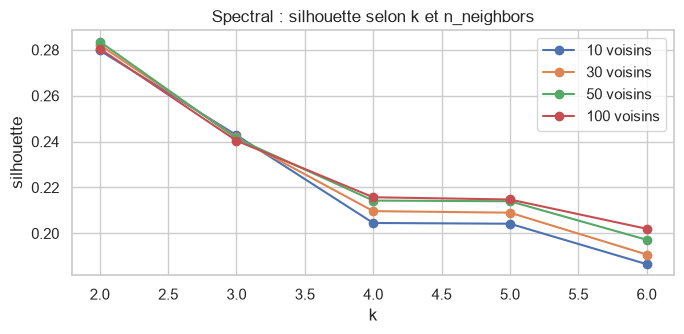

In [30]:
spectral_rows = []
for n_neighbors in [10, 30, 50, 100]:
    for k in range(2, 7):
        model = SpectralClustering(n_clusters=k, affinity="nearest_neighbors",
                                   n_neighbors=n_neighbors, random_state=RS)
        lab = model.fit_predict(X_std["8"])
        spectral_rows.append({
            "n_neighbors": n_neighbors, "k": k,
            "silhouette": silhouette_score(X_std["8"], lab),
            "Calinski-Harabasz": calinski_harabasz_score(X_std["8"], lab),
            "plus petit groupe": np.bincount(lab).min(),
        })
spectral_scan = pd.DataFrame(spectral_rows)

print("--- Silhouette ---")
display(spectral_scan.pivot(index="n_neighbors", columns="k", values="silhouette").round(3))
print("--- Taille du plus petit groupe (graines) ---")
display(spectral_scan.pivot(index="n_neighbors", columns="k", values="plus petit groupe"))
print("--- Calinski-Harabasz ---")
display(spectral_scan.pivot(index="n_neighbors", columns="k", values="Calinski-Harabasz").round(0))

fig, ax = plt.subplots(figsize=(7, 3.5))
for nn in spectral_scan["n_neighbors"].unique():
    d = spectral_scan[spectral_scan["n_neighbors"] == nn]
    ax.plot(d["k"], d["silhouette"], "o-", label=f"{nn} voisins")
ax.set_xlabel("k"); ax.set_ylabel("silhouette"); ax.set_title("Spectral : silhouette selon k et n_neighbors")
ax.legend(); plt.tight_layout(); plt.show()

**Lecture.** Le résultat est **très stable** quand on change le nombre de voisins : pour `k = 2`, la silhouette reste entre 0,280 et 0,284 de 10 à 100 voisins, et le plus petit groupe compte entre 1 170 et 1 200 graines (soit environ 47 à 48 % du lot) : les deux groupes sont **équilibrés**. La silhouette diminue ensuite quand `k` augmente (≈ 0,24 pour `k = 3`, ≈ 0,21 pour `k = 4`). Comme pour K-means et Ward, `k = 2` est le meilleur choix. Nous retenons **`n_neighbors = 30` et `k = 2`**, un compromis entre un graphe trop fragmenté et un graphe trop dense.

#### 3.3 Autre graphe : noyau gaussien (RBF)

Pour vérifier que le résultat ne dépend pas seulement du graphe de voisinage, nous testons le noyau RBF, de paramètre `gamma` : plus `gamma` est grand, plus une graine n'est reliée qu'à ses voisines très proches. Ce réglage est délicat : si `gamma` est mal choisi, le graphe devient quasi vide (ou quasi complet) et les groupes peuvent être déséquilibrés. Nous regardons donc les tailles de groupes en plus de la silhouette.

In [31]:
rbf_rows = []
rbf_labels = {}
for g in [0.01, 0.05, 0.1, 0.2]:
    lab = SpectralClustering(n_clusters=2, affinity="rbf", gamma=g, random_state=RS).fit_predict(X_std["8"])
    rbf_labels[g] = lab
    rbf_rows.append({"gamma": g,
                     "silhouette": silhouette_score(X_std["8"], lab),
                     "Calinski-Harabasz": calinski_harabasz_score(X_std["8"], lab),
                     "tailles": str(np.bincount(lab).tolist())})
display(pd.DataFrame(rbf_rows).round(3))

lab_knn30 = SpectralClustering(n_clusters=2, affinity="nearest_neighbors", n_neighbors=30,
                               random_state=RS).fit_predict(X_std["8"])
print("Accord (ARI) entre le noyau RBF et le graphe de 30 voisins :")
for g, lab in rbf_labels.items():
    print(f"  gamma = {g:<5} -> ARI = {adjusted_rand_score(lab_knn30, lab):.2f}")

,gamma,silhouette,Calinski-Harabasz,tailles
0,0.01,0.307,1101.745,"[1575, 925]"
1,0.05,0.313,1093.838,"[1643, 857]"
2,0.10,0.317,1049.691,"[1758, 742]"
3,0.20,0.704,87.184,"[2495, 5]"


Accord (ARI) entre le noyau RBF et le graphe de 30 voisins :
  gamma = 0.01  -> ARI = 0.63
  gamma = 0.05  -> ARI = 0.54
  gamma = 0.1   -> ARI = 0.42
  gamma = 0.2   -> ARI = -0.00


**Lecture.** Le noyau RBF demande de **régler `gamma`** : on voit dans le tableau comment les silhouettes, les tailles de groupes et l'accord avec le graphe de voisinage évoluent avec ce paramètre. Le graphe des plus proches voisins n'a pas ce défaut : son résultat reste quasiment identique de 10 à 100 voisins (voir 3.2). Nous gardons donc le graphe de **30 voisins** pour la suite, ce qui évite de dépendre d'un réglage fin.

#### 3.4 Résultat du clustering spectral avec k = 2 (8 variables, 30 voisins)

Effectifs spectral : [1318 1182]
Silhouette : 0.282
Calinski-Harabasz : 1056.0
Graines avec une silhouette négative : 240 sur 2500


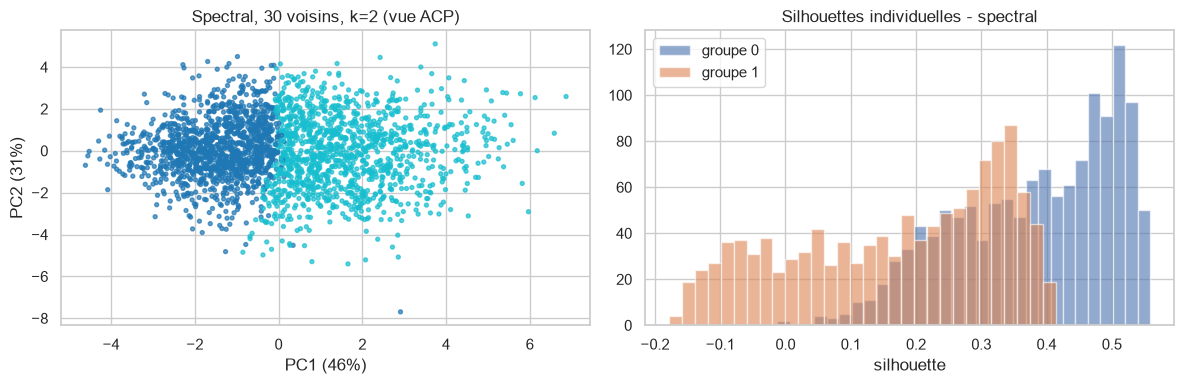

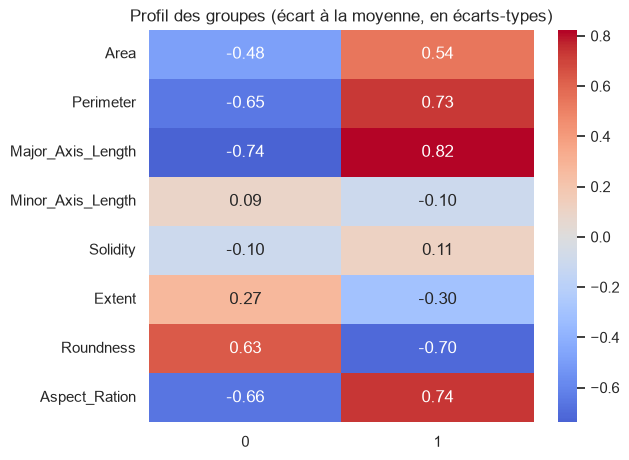

,groupe 0 (n=1318),groupe 1 (n=1182)
Area,74059.38,88016.32
Perimeter,1059.03,1209.72
Major_Axis_Length,415.05,502.93
Minor_Axis_Length,227.93,223.41
Solidity,0.99,0.99
Extent,0.71,0.67
Roundness,0.83,0.75
Aspect_Ration,1.83,2.27


In [32]:
spectral2 = SpectralClustering(n_clusters=2, affinity="nearest_neighbors", n_neighbors=30, random_state=RS)
labels_spectral = spectral2.fit_predict(X_std["8"])
print("Effectifs spectral :", np.bincount(labels_spectral))
print("Silhouette :", round(silhouette_score(X_std["8"], labels_spectral), 3))
print("Calinski-Harabasz :", round(calinski_harabasz_score(X_std["8"], labels_spectral), 1))

sil_sp = silhouette_samples(X_std["8"], labels_spectral)
print("Graines avec une silhouette négative :", (sil_sp < 0).sum(), "sur", len(sil_sp))

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
plot_pca("8", labels_spectral, "Spectral, 30 voisins, k=2 (vue ACP)", ax[0])
for c in range(2):
    ax[1].hist(sil_sp[labels_spectral == c], bins=30, alpha=0.6, label=f"groupe {c}")
ax[1].set_title("Silhouettes individuelles - spectral")
ax[1].set_xlabel("silhouette"); ax[1].legend()
plt.tight_layout(); plt.show()

profile("8", labels_spectral)

**Résultat du spectral, k = 2, 8 variables.** Le clustering spectral retrouve les mêmes tendances que K-means, avec des groupes **plus équilibrés** (1 318 et 1 182 graines, contre 1 551 et 949) :

- un groupe de graines **plus petites, courtes et arrondies** : aire ≈ 74 100, longueur ≈ 415, rapport longueur/largeur ≈ 1,83, rondeur ≈ 0,83 ;
- un groupe de graines **plus grandes, longues et allongées** : aire ≈ 88 000, longueur ≈ 503, rapport ≈ 2,27, rondeur ≈ 0,75.

Comme pour K-means, la **largeur** est presque identique dans les deux groupes (≈ 228 contre ≈ 223) : c'est la longueur qui sépare. Sa silhouette (0,282) est un peu plus basse que celle de K-means (0,306) et son indice de Calinski-Harabasz aussi (1 056 contre 1 106). Cela confirme que la structure générale **ne dépend pas uniquement d'une séparation par centres** : une méthode fondée sur un graphe de voisinage aboutit au même type de découpage.

#### 3.5 Une lecture plus fine : k = 3 (8 variables, 30 voisins)

Effectifs spectral k=3 : [595 927 978]
Silhouette k=3 : 0.242


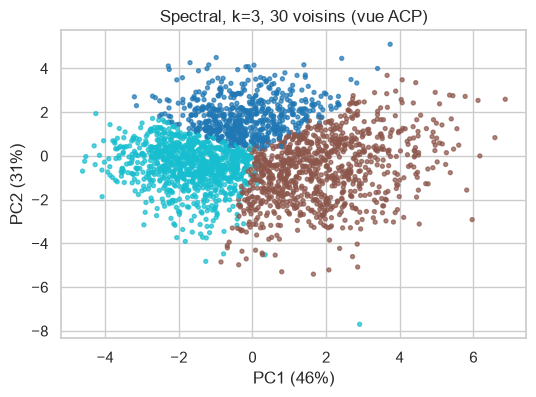

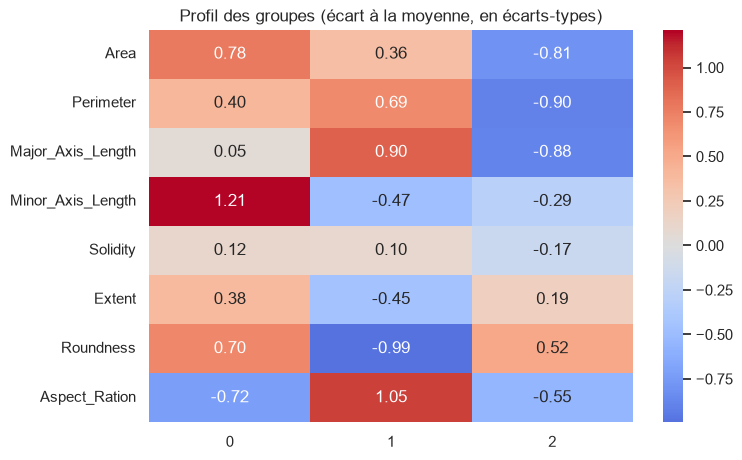

,groupe 0 (n=595),groupe 1 (n=927),groupe 2 (n=978)
Area,91253.05,85511.33,69612.46
Perimeter,1174.38,1205.31,1032.32
Major_Axis_Length,459.45,507.21,406.90
Minor_Axis_Length,254.03,214.78,219.06
Solidity,0.99,0.99,0.99
Extent,0.72,0.67,0.71
Roundness,0.83,0.74,0.82
Aspect_Ration,1.81,2.37,1.87


In [33]:
spectral3 = SpectralClustering(n_clusters=3, affinity="nearest_neighbors", n_neighbors=30, random_state=RS)
labels_spectral3 = spectral3.fit_predict(X_std["8"])
print("Effectifs spectral k=3 :", np.bincount(labels_spectral3))
print("Silhouette k=3 :", round(silhouette_score(X_std["8"], labels_spectral3), 3))

fig, ax = plt.subplots(figsize=(6, 4))
plot_pca("8", labels_spectral3, "Spectral, k=3, 30 voisins (vue ACP)", ax)
plt.show()
profile("8", labels_spectral3)

**Lecture avec k = 3.** Avec `k = 3`, la silhouette (≈ 0,24) est plus faible qu'avec `k = 2` (0,28), et le plus petit groupe compte 595 graines : le troisième groupe n'est donc pas un simple petit îlot d'outliers, mais un vrai sous-ensemble du lot. Les profils détaillés ci-dessus (moyennes en unités d'origine) permettent de voir quelle dimension (taille ou forme) il ajoute. Comme pour les deux autres méthodes, `k = 3` reste une **lecture complémentaire** : le gain en finesse se paie par une perte de netteté.

#### 3.6 Bilan du clustering spectral

- Le graphe des **30 voisins** donne un résultat très stable vis-à-vis du réglage (10 à 100 voisins) ; le noyau RBF dépend davantage de `gamma`.
- Le spectre du laplacien ne montre **pas de saut net** : pas de blocs séparés, mais un continuum, comme le dendrogramme.
- Avec `k = 2`, le spectral produit des groupes **équilibrés** et un découpage proche de K-means (même opposition « petites et arrondies » / « grandes et allongées »).
- Il est **plus coûteux** (construction du graphe et décomposition en valeurs propres) pour un gain faible par rapport à K-means sur ces données, dont la structure est plutôt de type « nuage compact » que de type « formes enchevêtrées ».

### <font color='#2E5A7A'>4. Comparaison des trois méthodes</font>

Pour choisir la méthode la plus pertinente, nous comparons **K-means** (`k = 2`, `n_init=20`), **Ward** (`k = 2`) et le **clustering spectral** (graphe de 30 voisins, `k = 2`), tous sur les **mêmes 8 variables standardisées**, avec les paramètres retenus dans leurs sections.

#### 4.1 Critères internes et équilibre des groupes

,Silhouette (k=2),Calinski-Harabasz (k=2),Silhouette (k=3),Tailles des groupes,Plus petit groupe (%),Silhouette négative (%)
Méthode,,,,,,
K-means,0.306,1106,0.254,"[1551, 949]",38.0,4.0
Ward,0.231,810,0.198,"[1194, 1306]",47.8,13.6
Spectral (30 voisins),0.282,1056,0.242,"[1318, 1182]",47.3,9.6


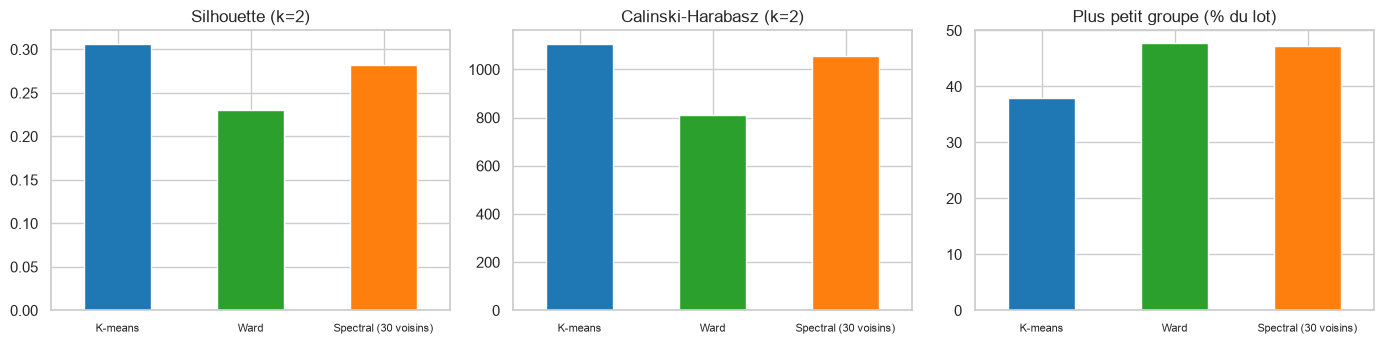

In [34]:
labs = {
    "K-means": labels_kmeans,
    "Ward": ward["8"].labels_,
    "Spectral (30 voisins)": labels_spectral,
}
labs3 = {
    "K-means": labels_kmeans3,
    "Ward": ward3.labels_,
    "Spectral (30 voisins)": labels_spectral3,
}

rows = []
for m, l in labs.items():
    s_i = silhouette_samples(X_std["8"], l)
    rows.append({
        "Méthode": m,
        "Silhouette (k=2)": silhouette_score(X_std["8"], l),
        "Calinski-Harabasz (k=2)": calinski_harabasz_score(X_std["8"], l),
        "Silhouette (k=3)": silhouette_score(X_std["8"], labs3[m]),
        "Tailles des groupes": str(np.bincount(l).tolist()),
        "Plus petit groupe (%)": 100 * np.bincount(l).min() / len(l),
        "Silhouette négative (%)": 100 * (s_i < 0).mean(),
    })
comp = pd.DataFrame(rows).set_index("Méthode")
display(comp.style.format({"Silhouette (k=2)": "{:.3f}", "Calinski-Harabasz (k=2)": "{:.0f}",
                           "Silhouette (k=3)": "{:.3f}", "Plus petit groupe (%)": "{:.1f}",
                           "Silhouette négative (%)": "{:.1f}"}))

fig, ax = plt.subplots(1, 3, figsize=(14, 3.6))
comp["Silhouette (k=2)"].plot.bar(ax=ax[0], color=["tab:blue", "tab:green", "tab:orange"], rot=0)
ax[0].set_title("Silhouette (k=2)")
comp["Calinski-Harabasz (k=2)"].plot.bar(ax=ax[1], color=["tab:blue", "tab:green", "tab:orange"], rot=0)
ax[1].set_title("Calinski-Harabasz (k=2)")
comp["Plus petit groupe (%)"].plot.bar(ax=ax[2], color=["tab:blue", "tab:green", "tab:orange"], rot=0)
ax[2].set_title("Plus petit groupe (% du lot)"); ax[2].set_ylim(0, 50)
for a in ax:
    a.set_xlabel(""); a.tick_params(axis="x", labelsize=8)
plt.tight_layout(); plt.show()

**Lecture.**

- **K-means** a la meilleure silhouette (0,306) et le meilleur indice de Calinski-Harabasz (1 106) ; le **spectral** suit de près (0,282 ; 1 056) ; **Ward** est nettement derrière (0,231 ; 810).
- Pour `k = 3`, l'ordre est le même (K-means 0,254, spectral 0,242, Ward 0,198) : aucune méthode ne trouve trois groupes plus nets que deux.
- Les **équilibres** diffèrent : le spectral et Ward donnent des groupes de tailles proches (≈ 47 % et 48 % pour le plus petit), K-means un groupe plus petit (38 %).
- Ces scores restent **modérés** pour les trois méthodes (autour de 0,2 à 0,3) : aucune ne trouve de groupes très nettement séparés, ce qui est cohérent avec ce que montraient le dendrogramme et le spectre du laplacien.

#### 4.2 Accord entre les méthodes

L'ARI compare deux partitions : 1 si elles sont identiques, 0 si l'accord est celui du hasard.

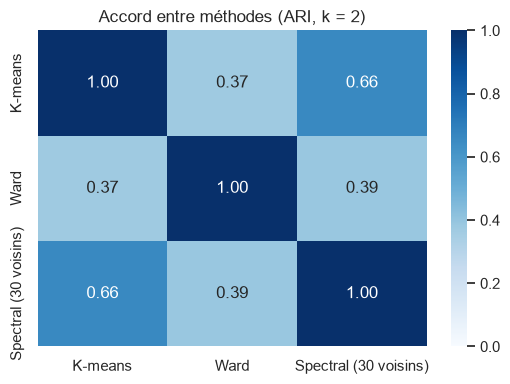

In [35]:
names = list(labs)
ari = pd.DataFrame([[adjusted_rand_score(labs[a], labs[b]) for b in names] for a in names],
                   index=names, columns=names)
plt.figure(figsize=(5.5, 4))
sns.heatmap(ari, annot=True, fmt=".2f", cmap="Blues", vmin=0, vmax=1)
plt.title("Accord entre méthodes (ARI, k = 2)")
plt.tight_layout(); plt.show()

**Lecture.** K-means et le spectral sont proches l'un de l'autre (ARI ≈ 0,66). Ward s'écarte davantage des deux autres (ARI ≈ 0,4) : il ne trace pas la frontière au même endroit. 
L'accord n'est donc que **partiel**, ce qui illustre le point central de l'analyse : il n'y a pas de frontière unique et évidente entre les groupes, mais une zone de transition dans laquelle chaque méthode place sa coupure à sa manière.

#### 4.3 Visualisation côte à côte

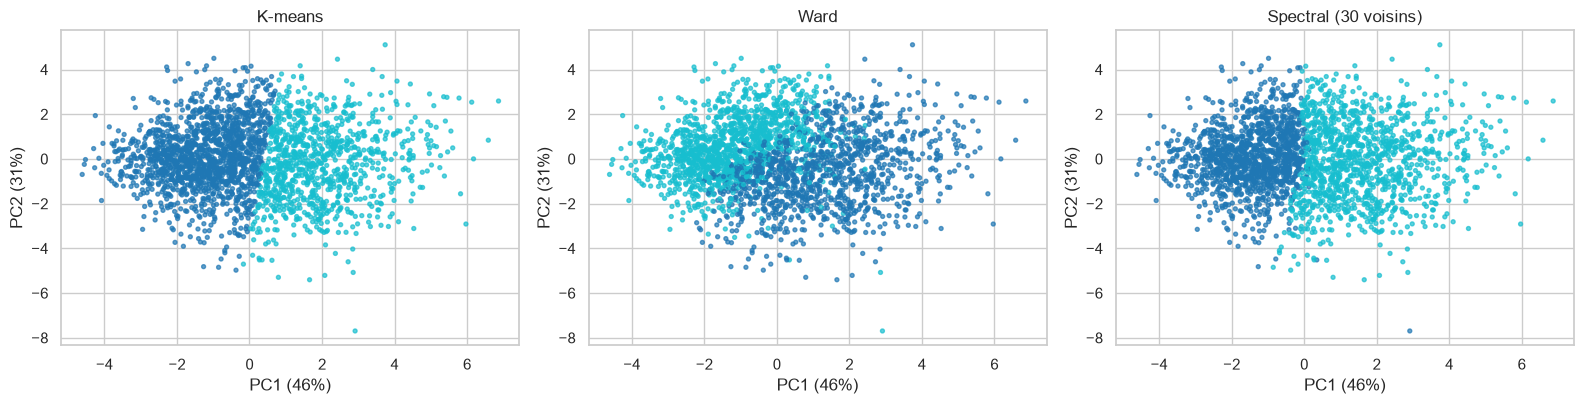

In [36]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4.2))
for a, (m, l) in zip(ax, labs.items()):
    plot_pca("8", l, m, a)
plt.tight_layout(); plt.show()

**Lecture.** Dans la projection ACP, les trois méthodes coupent le nuage dans le sens de l'axe **PC1** (axe « allongement / longueur »), ce qui confirme que la séparation principale est liée à l'allongement de la graine. Aucune des trois ne fait apparaître de vide entre les groupes : les nuages se touchent.

#### 4.4 Qu'est-ce qui sépare les groupes ?

Pour chaque méthode, nous comparons le groupe de graines **allongées** (rapport longueur/largeur le plus élevé) au groupe de graines **trapues**. Le graphique donne, pour chaque variable, l'écart entre les deux groupes en **écarts-types** : plus la barre est longue, plus la variable sépare les groupes.

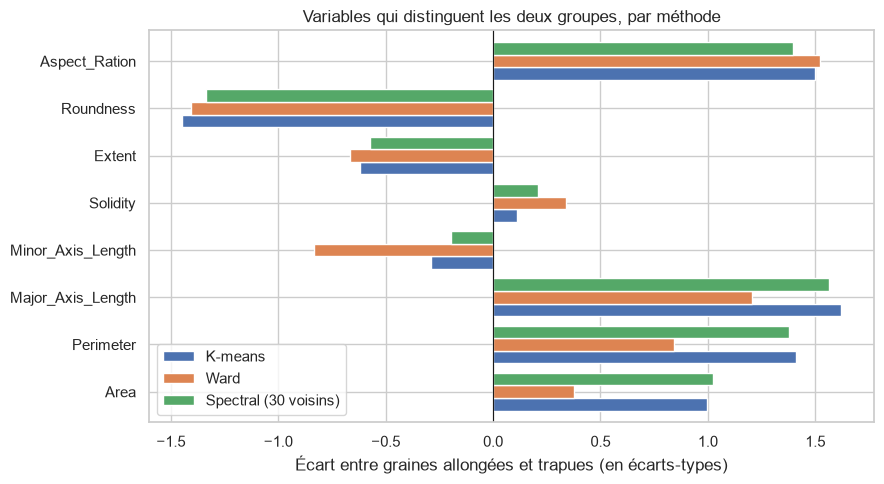

K-means                Ward           Spectral (30 voisins)          
                    trapues allongées   trapues allongées               trapues allongées
effectif            1551.00    949.00   1306.00   1194.00               1318.00   1182.00
Area               75491.29  89102.80  78187.54  83360.65              74059.38  88016.32
Perimeter           1071.74   1225.96   1086.31   1178.37               1059.03   1209.72
Major_Axis_Length    422.03    513.11    424.20    492.05                415.05    502.93
Minor_Axis_Length    228.36    221.60    235.06    215.66                227.93    223.41
Solidity               0.99      0.99      0.99      0.99                  0.99      0.99
Extent                 0.71      0.67      0.71      0.67                  0.71      0.67
Roundness              0.82      0.74      0.83      0.75                  0.83      0.75
Aspect_Ration          1.86      2.34      1.81      2.29                  1.83      2.27

In [37]:
def ecart_std(l):
    """Écart (en écarts-types) entre le groupe le plus allongé et le groupe le plus trapu."""
    zs = X_std["8"].groupby(l).mean()
    haut = zs["Aspect_Ration"].idxmax()
    bas = 1 - haut
    return zs.loc[haut] - zs.loc[bas]

ecarts = pd.DataFrame({m: ecart_std(l) for m, l in labs.items()})
ecarts.plot.barh(figsize=(9, 5), width=0.8)
plt.axvline(0, color="k", lw=0.8)
plt.xlabel("Écart entre graines allongées et trapues (en écarts-types)")
plt.title("Variables qui distinguent les deux groupes, par méthode")
plt.tight_layout(); plt.show()

# Moyennes en unités d'origine
tab = {}
for m, l in labs.items():
    g = df_sel.groupby(l).mean()
    haut = g["Aspect_Ration"].idxmax()
    tab[(m, "trapues")] = g.loc[1 - haut]
    tab[(m, "allongées")] = g.loc[haut]
tab = pd.DataFrame(tab)
effectifs = pd.DataFrame({(m, p): [int((np.asarray(l) == (g)).sum())]
                          for m, l in labs.items()
                          for p, g in [("trapues", 1 - df_sel.groupby(l)["Aspect_Ration"].mean().idxmax()),
                                       ("allongées", df_sel.groupby(l)["Aspect_Ration"].mean().idxmax())]},
                         index=["effectif"])
display(pd.concat([effectifs, tab]).round(2))

**Lecture.**

- **K-means** et **spectral** produisent des profils presque superposables : leurs groupes diffèrent surtout par la **longueur**, le **périmètre** et le **rapport longueur/largeur**, avec une aire plus grande pour le groupe allongé (≈ 89 000 contre ≈ 75 000 pour K-means) et une largeur presque inchangée. Ils séparent donc à la fois un effet de **taille** (liée à la longueur) et un effet d'**allongement**.
- **Ward** sépare davantage la **forme** que la taille : ses deux groupes ont des aires voisines (≈ 83 000 et ≈ 78 000) et se distinguent surtout par le rapport longueur/largeur, la rondeur et la largeur (≈ 216 contre ≈ 235).

Les trois méthodes s'accordent donc sur l'idée centrale (**trapu / arrondi** contre **allongé**), mais pas sur la part de la taille dans cette séparation.

#### 4.5 Stabilité

Nous testons la **stabilité** de chaque méthode : on la relance sur deux sous-échantillons aléatoires de 80 % des graines, puis on mesure l'accord (ARI) entre les deux résultats sur les graines communes (moyenne sur 10 tirages). Plus le score est proche de 1, plus la partition se reproduit d'un échantillon à l'autre.

,K-means,Ward,Spectral (30 voisins)
k=2,0.94,0.45,0.94
k=3,0.87,0.36,0.94


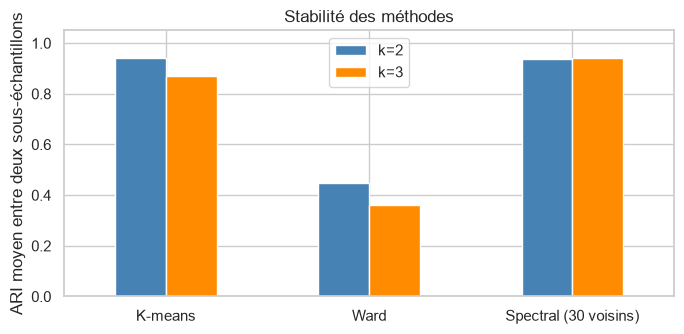

In [38]:
def stabilite(fit_predict, k, n_iter=10, f=0.8):
    rng = np.random.RandomState(RS)
    D = X_std["8"].values
    n = len(D)
    scores = []
    for _ in range(n_iter):
        i1 = rng.choice(n, int(f * n), replace=False)
        i2 = rng.choice(n, int(f * n), replace=False)
        commun = np.intersect1d(i1, i2)
        l1 = pd.Series(fit_predict(D[i1], k), index=i1)
        l2 = pd.Series(fit_predict(D[i2], k), index=i2)
        scores.append(adjusted_rand_score(l1[commun], l2[commun]))
    return np.mean(scores)

methodes = {
    "K-means": lambda D, k: KMeans(n_clusters=k, n_init=5, random_state=RS).fit_predict(D),
    "Ward": lambda D, k: AgglomerativeClustering(n_clusters=k, linkage="ward").fit_predict(D),
    "Spectral (30 voisins)": lambda D, k: SpectralClustering(n_clusters=k, affinity="nearest_neighbors",
                                                             n_neighbors=30, random_state=RS).fit_predict(D),
}
stab = pd.DataFrame({m: [stabilite(f, k) for k in (2, 3)] for m, f in methodes.items()},
                    index=["k=2", "k=3"])
display(stab.round(2))

ax = stab.T.plot.bar(figsize=(7, 3.5), rot=0, color=["steelblue", "darkorange"])
ax.set_ylabel("ARI moyen entre deux sous-échantillons"); ax.set_ylim(0, 1.05)
ax.set_title("Stabilité des méthodes"); plt.tight_layout(); plt.show()

**Lecture.** C'est la différence la plus nette entre les méthodes. Avec `k = 2`, **K-means et le spectral se reproduisent presque à l'identique** d'un sous-échantillon à l'autre (score ≈ 0,94), alors que **Ward est bien moins stable** (≈ 0,45). Sa frontière passe probablement dans une zone dense de graines intermédiaires et bouge d'un échantillon à l'autre. À `k = 3`, K-means et le spectral restent stables (0,87 et 0,94) alors que Ward descend à 0,36.

#### 4.6 Sensibilité au choix des variables (12 contre 8)

Pour chaque méthode, nous comparons le résultat obtenu avec 12 variables à celui obtenu avec 8 variables : part de graines qui **changent de groupe** et ARI entre les deux partitions (même protocole que celui utilisé pour Ward en 2.6).

,Graines qui changent de groupe,Part du lot (%),ARI 12 vs 8
Méthode,,,
K-means,121,4.8,0.82
Ward,332,13.3,0.54
Spectral (30 voisins),38,1.5,0.94


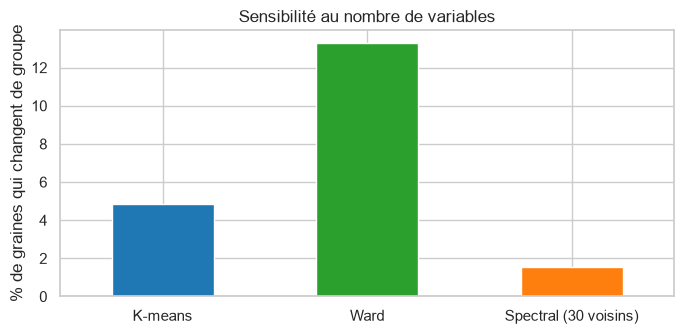

In [39]:
rows = []
for m_label, m_key in [("K-means", "K-means"), ("Ward", "Ward"), ("Spectral (30 voisins)", "Spectral kNN")]:
    l8 = labels_by_set["8 variables"][m_key]
    l12 = aligner(labels_by_set["12 variables"][m_key], l8)
    rows.append({"Méthode": m_label,
                 "Graines qui changent de groupe": int((l12 != l8).sum()),
                 "Part du lot (%)": 100 * (l12 != l8).mean(),
                 "ARI 12 vs 8": adjusted_rand_score(l12, l8)})
sens = pd.DataFrame(rows).set_index("Méthode")
display(sens.style.format({"Part du lot (%)": "{:.1f}", "ARI 12 vs 8": "{:.2f}"}))

fig, ax = plt.subplots(figsize=(7, 3.5))
sens["Part du lot (%)"].plot.bar(ax=ax, color=["tab:blue", "tab:green", "tab:orange"], rot=0)
ax.set_ylabel("% de graines qui changent de groupe")
ax.set_title("Sensibilité au nombre de variables"); ax.set_xlabel("")
plt.tight_layout(); plt.show()

**Lecture.** Ce tableau quantifie, pour les trois méthodes, la part de graines dont le groupe dépend de la sélection de variables. Pour Ward, nous avions trouvé environ 13 % (332 graines) en 2.6 ; le tableau permet de comparer ce chiffre à celui de K-means et du spectral. Plus cette part est faible, plus la méthode est robuste au choix des variables. Dans tous les cas, les graines concernées sont celles qui se trouvent près de la frontière entre les groupes.

#### 4.7 Graines « consensuelles » et graines « incertaines »

Les trois méthodes ne placent pas la frontière au même endroit (ARI de 0,4 à 0,7). Nous repérons donc les graines **classées pareil par les trois méthodes** (profil clair) et celles sur lesquelles les méthodes **divergent** (profil intermédiaire). Les numéros de groupes étant arbitraires, nous alignons d'abord les trois partitions sur celle de K-means.

Graines classées pareil par les trois méthodes : 1902 sur 2500 (76.1%)
Graines sur lesquelles les méthodes divergent   : 598 (23.9%)


,consensuelles,incertaines,moyenne du lot
Area,80888.46,79925.91,80658.22
Perimeter,1132.49,1123.23,1130.28
Major_Axis_Length,457.57,453.52,456.60
Minor_Axis_Length,226.24,224.39,225.79
Solidity,0.99,0.99,0.99
Extent,0.70,0.68,0.69
Roundness,0.79,0.79,0.79
Aspect_Ration,2.04,2.04,2.04


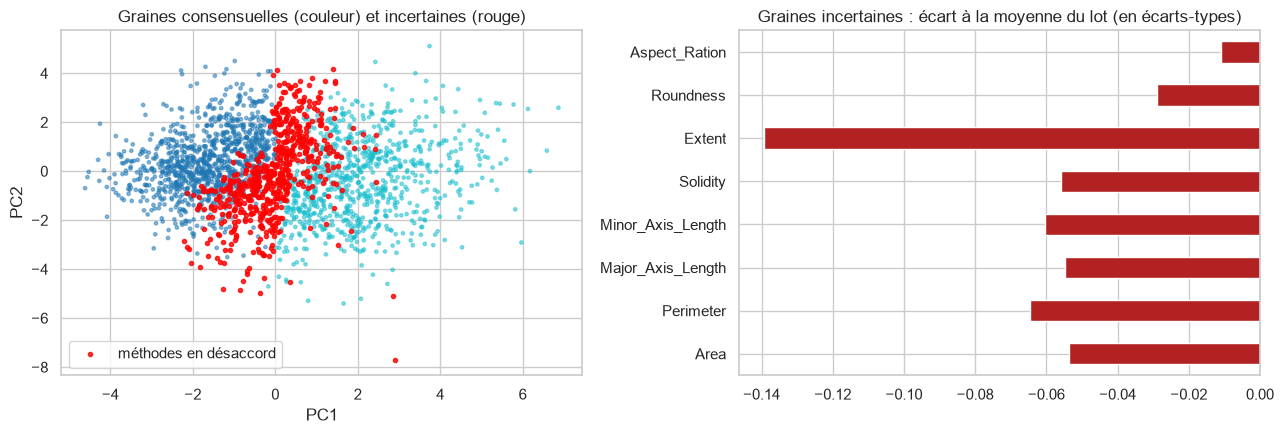

In [40]:
ref = labs["K-means"]
al = {m: aligner(np.asarray(l), ref) for m, l in labs.items()}
accord = (al["K-means"] == al["Ward"]) & (al["K-means"] == al["Spectral (30 voisins)"])
print(f"Graines classées pareil par les trois méthodes : {accord.sum()} sur {len(accord)} ({accord.mean():.1%})")
print(f"Graines sur lesquelles les méthodes divergent   : {(~accord).sum()} ({(~accord).mean():.1%})")

fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
ax[0].scatter(Zn["8"][accord, 0], Zn["8"][accord, 1], c=ref[accord], cmap="tab10", s=6, alpha=0.5)
ax[0].scatter(Zn["8"][~accord, 0], Zn["8"][~accord, 1], c="red", s=9, alpha=0.8, label="méthodes en désaccord")
ax[0].set_xlabel("PC1"); ax[0].set_ylabel("PC2"); ax[0].legend()
ax[0].set_title("Graines consensuelles (couleur) et incertaines (rouge)")

comp_cons = pd.DataFrame({
    "consensuelles": df_sel[accord].mean(),
    "incertaines": df_sel[~accord].mean(),
    "moyenne du lot": df_sel.mean(),
})
display(comp_cons.round(2))

z_unc = ((df_sel[~accord].mean() - df_sel.mean()) / df_sel.std())
z_unc.plot.barh(ax=ax[1], color="firebrick")
ax[1].axvline(0, color="k", lw=0.8)
ax[1].set_title("Graines incertaines : écart à la moyenne du lot (en écarts-types)")
plt.tight_layout(); plt.show()

**Lecture.** La figure et le tableau permettent de caractériser les graines « difficiles » : celles qui ne sont pas classées de la même façon par les trois méthodes. La proportion est affichée ci-dessus. Ce sont, par construction, des graines **proches de la frontière** entre les deux profils. Pour un tri automatique, ce sont celles qu'il faudrait traiter avec prudence (les mettre de côté, ou les évaluer avec un critère supplémentaire), alors que les graines consensuelles peuvent être attribuées à leur groupe avec une bonne confiance.

#### 4.8 Synthèse comparative

| Critère | K-means (k = 2) | Ward (k = 2) | Spectral (30 voisins, k = 2) |
|---|---|---|---|
| Silhouette | **0,306** | 0,231 | 0,282 |
| Calinski-Harabasz | **1 106** | 810 | 1 056 |
| Équilibre des groupes | 1 551 / 949 | **1 194 / 1 306** | 1 318 / 1 182 |
| Stabilité (sous-échantillons) | **≈ 0,94** | ≈ 0,45 | **≈ 0,94** |
| Sensibilité au choix du lien ou du noyau | faible (initialisations multiples) | **très forte** (3 liens sur 4 inutilisables) | faible avec le graphe de voisinage, plus forte avec le noyau RBF |
| Sensibilité 12 contre 8 variables | voir 4.6 | ≈ 13 % de graines changent de groupe | voir 4.6 |
| Ce qui sépare les groupes | longueur et allongement (+ taille) | forme (rapport, rondeur, largeur) | longueur et allongement (+ taille) |
| Information supplémentaire | centres interprétables | **dendrogramme** : division principale puis continuum | spectre du laplacien (connexité) |
| Coût de calcul | **faible** | moyen | élevé |
| Interprétabilité | **très simple** | simple | plus technique |

#### 4.9 Choix de la méthode

- **Pour résumer le lot en deux profils stables, nous recommandons K-means (`k = 2`, 8 variables standardisées)** : meilleure silhouette, meilleur indice de Calinski-Harabasz, partition qui se reproduit d'un sous-échantillon à l'autre, calcul rapide et profils faciles à expliquer à un non-spécialiste.
- Le **clustering spectral** est un **excellent contrôle** : il aboutit à un découpage très proche (ARI ≈ 0,66 avec K-means, même stabilité) avec des groupes plus équilibrés. Qu'une méthode fondée sur un graphe de voisinage retrouve la même structure qu'une méthode fondée sur des centres est un argument de **robustesse**. Son coût plus élevé n'est toutefois pas justifié ici par un gain net.
- Le **clustering hiérarchique (Ward)** est moins performant comme partition finale (moins stable, frontière fragile), mais il est **très utile pour comprendre** : son dendrogramme montre une division principale suivie d'un continuum, et ses groupes mettent en évidence le rôle de la **forme**. Nous le présentons comme un outil d'**exploration et d'explication**.

## **<font color='#2E5A7A'>III. Conclusion</font>**

- <font color='steelblue'>Conclure sur les informations que vous avez pu dégager du jeu de données.
</font>

**Démarche.** Nous avons traité le lot de 2 500 graines comme un analyste qui découvre des données sans étiquette : la colonne `Class` a été retirée dès l'import et n'est jamais utilisée. Les 12 mesures ont été standardisées ; une analyse de corrélation a montré deux blocs redondants (taille et allongement), d'où la comparaison entre 12 variables et 8 variables. Trois méthodes (K-means, clustering hiérarchique, clustering spectral) ont été appliquées avec les mêmes données et jugées avec les mêmes outils : silhouette, indice de Calinski-Harabasz, taille des groupes, profils, accord entre méthodes (ARI) et stabilité sur sous-échantillons.

**Ce que chaque méthode permet de dire.**

- **K-means.** La silhouette et l'indice de Calinski-Harabasz désignent `k = 2` (silhouette 0,306), alors que la méthode du coude ne montre aucune cassure nette. Les deux groupes opposent des graines **plus petites, courtes et arrondies** (62 % du lot) à des graines **plus grandes, longues et allongées** (38 %) ; la largeur est quasiment la même dans les deux groupes. Avec `k = 3`, une dimension de **taille** apparaît (petites, grandes et larges, longues et étroites), au prix d'une moindre netteté (silhouette 0,254).
- **Clustering hiérarchique.** Le **lien** est décisif : `single`, `complete` et `average` isolent une ou deux graines extrêmes (leurs silhouettes d'environ 0,8 sont trompeuses), et seul **Ward** donne des groupes équilibrés. Le dendrogramme, la silhouette et Calinski-Harabasz désignent `k = 2`. Ward sépare des graines **allongées** (≈ 48 %, rapport longueur/largeur ≈ 2,3) et des graines **plus trapues** (≈ 52 %, rapport ≈ 1,8), avec une faible différence de taille : c'est la **forme** qui sépare le lot. Environ 13 % des graines changent de groupe entre 12 et 8 variables.
- **Clustering spectral.** Avec un graphe de 30 plus proches voisins, le résultat est très stable vis-à-vis du réglage (10 à 100 voisins) et donne des groupes équilibrés (1 318 et 1 182 graines) très proches de ceux de K-means. Le spectre du laplacien ne montre pas de saut net : pas de blocs séparés, mais un continuum.

**Comparaison.** Les trois méthodes retrouvent la même tendance : un profil **trapu et arrondi** et un profil **allongé**. K-means et le spectral sont proches (ARI ≈ 0,66) et très stables (≈ 0,94), alors que Ward s'en écarte (ARI ≈ 0,4) et se reproduit bien moins d'un sous-échantillon à l'autre (≈ 0,45). K-means obtient les meilleurs scores internes (silhouette 0,306 ; Calinski-Harabasz 1 106), devant le spectral (0,282 ; 1 056) et Ward (0,231 ; 810). Les trois méthodes ne s'accordent pas sur la part de la taille dans la séparation : K-means et le spectral séparent à la fois longueur et allongement, Ward surtout la forme.

**Décision finale.** Pour la description générale du lot, nous retenons **K-means avec `k = 2` sur les 8 variables standardisées** : il est le meilleur compromis entre qualité interne, stabilité, simplicité, rapidité et interprétabilité. Le **spectral** confirme cette structure avec une méthode de nature différente. **Ward** est conservé comme outil d'exploration : son dendrogramme et ses profils expliquent le rôle de la forme et montrent la structure en « une division principale puis un continuum ».

**Connaissance pour le domaine.** Le lot ne se compose pas de deux catégories nettement séparées : il présente un **continuum de formes** avec **deux tendances principales**, des graines allongées et des graines plus trapues, et une **zone de transition** qui contient une part non négligeable des graines. Les silhouettes modérées (0,2 à 0,3), l'absence de vide entre les nuages dans l'ACP, l'absence de saut dans le spectre du laplacien et le désaccord partiel entre méthodes vont tous dans ce sens. La **longueur** de la graine et son **allongement** sont les variables qui séparent le plus ; la largeur varie peu d'un groupe à l'autre. Pour un tri automatique, les graines proches de la frontière (celles sur lesquelles les méthodes divergent) devraient être traitées avec prudence : mises de côté, ou évaluées avec un critère supplémentaire.

**Limites.**

- Les scores de silhouette sont modérés pour les trois méthodes : les groupes décrivent des **tendances**, pas des catégories étanches.
- K-means favorise des groupes compacts et arrondis ; Ward cherche des groupes de variance comparable et reste sensible à la sélection des variables et à l'échantillon ; le spectral dépend du graphe choisi.
- Les variables sont uniquement **géométriques** (aucune information de couleur, de texture ou de provenance) : les groupes sont des **profils de forme** et ne peuvent pas être assimilés à des variétés biologiques sans information externe.
- Les valeurs extrêmes ont été conservées ; certaines méthodes (liens `single`, `complete`, `average`) y sont très sensibles.

**Perspectives.** Une suite naturelle serait de confronter ces profils à des informations externes sur les variétés ou les lots de graines (ce que nous avons volontairement évité ici), d'ajouter des mesures de couleur ou de texture, et de tester d'autres méthodes (mélanges gaussiens, DBSCAN) pour mieux modéliser la zone intermédiaire.